In [1]:
# Quick test - basic imports
import sys
print(f"Python version: {sys.version}")
print("Basic import successful!")

Python version: 3.12.7 (main, Oct  1 2024, 02:05:46) [Clang 15.0.0 (clang-1500.3.9.4)]
Basic import successful!


## 1. Import Required Libraries

In [2]:
# Data manipulation and analysis
import pandas as pd
import numpy as np
from pathlib import Path
import sys
import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Scikit-learn utilities
import sklearn
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, chi2, RFE, mutual_info_classif
from sklearn.decomposition import PCA

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

# Advanced ML libraries (optional - install libomp via brew if needed)
try:
    import xgboost as xgb
    print("✓ XGBoost imported successfully")
except Exception as e:
    print(f"⚠ XGBoost not available. Run: brew install libomp")
    xgb = None

try:
    import lightgbm as lgb
    print("✓ LightGBM imported successfully")
except Exception as e:
    print(f"⚠ LightGBM not available: {str(e)[:50]}...")
    lgb = None

try:
    from catboost import CatBoostClassifier
    print("✓ CatBoost imported successfully")
except Exception as e:
    print(f"⚠ CatBoost not available: {str(e)[:50]}...")
    CatBoostClassifier = None

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve, auc,
    confusion_matrix, classification_report, matthews_corrcoef
)

# Handling imbalanced data
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek

# Model interpretation
try:
    import shap
    print("✓ SHAP imported successfully")
except Exception as e:
    print(f"⚠ SHAP not available: {str(e)[:50]}...")
    shap = None

try:
    from lime import lime_tabular
    print("✓ LIME imported successfully")
except Exception as e:
    print(f"⚠ LIME not available: {str(e)[:50]}...")
    lime_tabular = None

# Model persistence
import joblib
import pickle

# Statistical analysis
from scipy import stats
from scipy.stats import zscore

# Date handling
from datetime import datetime

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

print("\n" + "="*60)
print("✓ Core libraries imported successfully!")
print("="*60)
print(f"Python version: {sys.version}")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Scikit-learn version: {sklearn.__version__}")
print("="*60)

⚠ XGBoost not available. Run: brew install libomp
⚠ LightGBM not available: dlopen(/Users/roya/Desktop/Thesis/.venv/lib/python...
✓ CatBoost imported successfully
✓ SHAP imported successfully
✓ LIME imported successfully

✓ Core libraries imported successfully!
Python version: 3.12.7 (main, Oct  1 2024, 02:05:46) [Clang 15.0.0 (clang-1500.3.9.4)]
Pandas version: 2.3.3
NumPy version: 2.3.5
Scikit-learn version: 1.8.0
✓ SHAP imported successfully
✓ LIME imported successfully

✓ Core libraries imported successfully!
Python version: 3.12.7 (main, Oct  1 2024, 02:05:46) [Clang 15.0.0 (clang-1500.3.9.4)]
Pandas version: 2.3.3
NumPy version: 2.3.5
Scikit-learn version: 1.8.0


## 2. Define File Paths and Configuration

In [3]:
# Base directory
BASE_DIR = Path('/Users/roya/Desktop/Thesis')
DATA_DIR = BASE_DIR / 'Data set'
OUTPUT_DIR = BASE_DIR / 'Thesis_Project' / 'ML'

# Data file paths
PART_B_FILE = DATA_DIR / 'Part B' / '2023' / 'MUP_PHY_R25_P05_V20_D23_Prov_Svc.csv'
PART_D_FILE = DATA_DIR / 'Medicare Part D Prescribers - by Provider and Drug' / '2023' / 'MUP_DPR_RY25_P04_V10_DY23_NPIBN.csv'
OIG_FILE = DATA_DIR / 'OIG.csv'

# Create output directories
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / 'models').mkdir(exist_ok=True)
(OUTPUT_DIR / 'figures').mkdir(exist_ok=True)
(OUTPUT_DIR / 'reports').mkdir(exist_ok=True)

print("✓ File paths configured")
print(f"Base Directory: {BASE_DIR}")
print(f"Data Directory: {DATA_DIR}")
print(f"Output Directory: {OUTPUT_DIR}")

✓ File paths configured
Base Directory: /Users/roya/Desktop/Thesis
Data Directory: /Users/roya/Desktop/Thesis/Data set
Output Directory: /Users/roya/Desktop/Thesis/Thesis_Project/ML


## 3. Data Loading & Initial Exploration

### 3.1 Load Medicare Part B Data

In [5]:
# Load Part B data (Provider Services)
print("Loading Medicare Part B 2023 data...")
part_b_df = pd.read_csv(PART_B_FILE, low_memory=False)

print(f"Part B Data Shape: {part_b_df.shape}")
print(f"\nMemory Usage: {part_b_df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
part_b_df.head()

Loading Medicare Part B 2023 data...
Part B Data Shape: (9660647, 28)
Part B Data Shape: (9660647, 28)

Memory Usage: 11188.00 MB

Memory Usage: 11188.00 MB


,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_MI,Rndrng_Prvdr_Crdntls,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_St1,Rndrng_Prvdr_St2,Rndrng_Prvdr_City,Rndrng_Prvdr_State_Abrvtn,Rndrng_Prvdr_State_FIPS,Rndrng_Prvdr_Zip5,Rndrng_Prvdr_RUCA,Rndrng_Prvdr_RUCA_Desc,Rndrng_Prvdr_Cntry,Rndrng_Prvdr_Type,Rndrng_Prvdr_Mdcr_Prtcptg_Ind,HCPCS_Cd,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
0,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,24,20817,1.0000,Metropolitan area core: primary flow within an...,US,Hospitalist,Y,99221,Initial hospital care with straightforward or ...,N,F,12,12.0000,12,250.2267,89.0625,60.3125,54.6692
1,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,24,20817,1.0000,Metropolitan area core: primary flow within an...,US,Hospitalist,Y,99222,Initial hospital care with straightforward or ...,N,F,22,22.0000,22,318.5818,130.3127,99.3800,98.4295
2,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,24,20817,1.0000,Metropolitan area core: primary flow within an...,US,Hospitalist,Y,99231,Subsequent hospital care with straightforward ...,N,F,76,127.0000,127,95.7323,54.8202,43.5573,38.7487
3,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,24,20817,1.0000,Metropolitan area core: primary flow within an...,US,Hospitalist,Y,99232,Subsequent hospital care with moderate levelof...,N,F,180,341.0000,341,194.4415,86.8408,69.0864,61.8123
4,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,24,20817,1.0000,Metropolitan area core: primary flow within an...,US,Hospitalist,Y,99233,Subsequent hospital care with moderate levelof...,N,F,53,79.0000,79,251.4541,127.9152,100.9432,92.4091


In [5]:
part_b_df['Place_Of_Srvc'].unique()

array(['F', 'O'], dtype=object)

remove = ['Rndrng_Prvdr_Last_Org_Name', 'Rndrng_Prvdr_First_Name', 'Rndrng_Prvdr_MI',	'Rndrng_Prvdr_St1', 'Rndrng_Prvdr_St2', 'Rndrng_Prvdr_City', 'Rndrng_Prvdr_State_FIPS', 'Rndrng_Prvdr_RUCA', 'Rndrng_Prvdr_RUCA_Desc', 'Rndrng_Prvdr_Cntry'  ]

keep = [ 'Rndrng_Prvdr_State_Abrvtn', 'Rndrng_Prvdr_Zip5', 'Rndrng_Prvdr_Ent_Cd', 'Rndrng_Prvdr_Crdntls', 'Rndrng_Prvdr_Type', 'HCPCS_Cd', 'Place_Of_Srvc', 'Tot_Benes',	'Tot_Srvcs', 'Tot_Bene_Day_Srvcs', 'Avg_Sbmtd_Chrg',	'Avg_Mdcr_Alowd_Amt', 	'Avg_Mdcr_Pymt_Amt', 	'Avg_Mdcr_Stdzd_Amt'   ]

In [6]:
# Basic information about Part B data
print("Part B Data Info:")
print("="*50)
part_b_df.info()

Part B Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9660647 entries, 0 to 9660646
Data columns (total 28 columns):
 #   Column                         Dtype  
---  ------                         -----  
 0   Rndrng_NPI                     int64  
 1   Rndrng_Prvdr_Last_Org_Name     object 
 2   Rndrng_Prvdr_First_Name        object 
 3   Rndrng_Prvdr_MI                object 
 4   Rndrng_Prvdr_Crdntls           object 
 5   Rndrng_Prvdr_Ent_Cd            object 
 6   Rndrng_Prvdr_St1               object 
 7   Rndrng_Prvdr_St2               object 
 8   Rndrng_Prvdr_City              object 
 9   Rndrng_Prvdr_State_Abrvtn      object 
 10  Rndrng_Prvdr_State_FIPS        object 
 11  Rndrng_Prvdr_Zip5              object 
 12  Rndrng_Prvdr_RUCA              float64
 13  Rndrng_Prvdr_RUCA_Desc         object 
 14  Rndrng_Prvdr_Cntry             object 
 15  Rndrng_Prvdr_Type              object 
 16  Rndrng_Prvdr_Mdcr_Prtcptg_Ind  object 
 17  HCPCS_Cd                    

In [7]:
# Descriptive statistics for Part B
part_b_df.describe()

,Rndrng_NPI,Rndrng_Prvdr_RUCA,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
count,9660647.0000,9653047.0000,9660647.0000,9660647.0000,9660647.0000,9660647.0000,9660647.0000,9660647.0000,9660647.0000
mean,1499463663.1307,1.5640,85.3712,273.8522,136.4925,416.8288,106.1070,82.9908,82.3740
std,287709561.5021,3.3527,1354.3709,6814.5889,2185.7863,1433.2747,322.3192,257.0740,258.1384
min,1003000126.0000,1.0000,11.0000,5.5000,11.0000,0.0001,0.0000,0.0000,0.0000
25%,1245948041.0000,1.0000,17.0000,21.0000,20.0000,71.9900,26.9947,20.8468,19.9300
50%,1497947444.0000,1.0000,32.0000,43.0000,40.0000,175.0000,71.3767,53.1022,53.6253
75%,1740786144.0000,1.0000,71.0000,116.0000,103.0000,356.0000,122.1174,92.0180,92.3253
max,1992999874.0000,99.0000,870486.0000,5208424.0000,1778281.0000,99999.9900,52794.0407,42059.5177,42229.3294


### 3.2 Load Medicare Part D Data

In [6]:
# Load Part D data (Prescription Drugs)
print("Loading Medicare Part D 2023 data...")
part_d_df = pd.read_csv(PART_D_FILE, low_memory=False)

print(f"Part D Data Shape: {part_d_df.shape}")
print(f"\nMemory Usage: {part_d_df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

part_d_df.head()

Loading Medicare Part D 2023 data...
Part D Data Shape: (26794878, 22)
Part D Data Shape: (26794878, 22)

Memory Usage: 18005.65 MB

Memory Usage: 18005.65 MB


,Prscrbr_NPI,Prscrbr_Last_Org_Name,Prscrbr_First_Name,Prscrbr_City,Prscrbr_State_Abrvtn,Prscrbr_State_FIPS,Prscrbr_Type,Prscrbr_Type_Src,Brnd_Name,Gnrc_Name,Tot_Clms,Tot_30day_Fills,Tot_Day_Suply,Tot_Drug_Cst,Tot_Benes,GE65_Sprsn_Flag,GE65_Tot_Clms,GE65_Tot_30day_Fills,GE65_Tot_Drug_Cst,GE65_Tot_Day_Suply,GE65_Bene_Sprsn_Flag,GE65_Tot_Benes
0,1003000126,Enkeshafi,Ardalan,Bethesda,MD,24,Hospitalist,Claim-Specialty,Eliquis,Apixaban,13,15.3000,437,8828.7400,NaN,#,NaN,NaN,NaN,NaN,*,NaN
1,1003000126,Enkeshafi,Ardalan,Bethesda,MD,24,Hospitalist,Claim-Specialty,Prednisone,Prednisone,14,14.0000,153,54.9800,14.0000,#,NaN,NaN,NaN,NaN,#,NaN
2,1003000142,Khalil,Rashid,Toledo,OH,39,Anesthesiology,Claim-Specialty,Acetaminophen-Codeine,Acetaminophen With Codeine,43,43.0000,1020,491.3800,12.0000,#,NaN,NaN,NaN,NaN,*,NaN
3,1003000142,Khalil,Rashid,Toledo,OH,39,Anesthesiology,Claim-Specialty,Amitriptyline Hcl,Amitriptyline Hcl,35,35.0000,1050,471.0100,15.0000,#,NaN,NaN,NaN,NaN,*,NaN
4,1003000142,Khalil,Rashid,Toledo,OH,39,Anesthesiology,Claim-Specialty,Baclofen,Baclofen,55,63.0000,1890,796.1000,23.0000,NaN,27.0000,29.0000,417.8600,870.0000,*,NaN


remove = ['Prscrbr_City', 'Prscrbr_State_FIPS', 'Prscrbr_Type_Src', 'Tot_Day_Suply', 'GE65_Sprsn_Flag', 'GE65_Bene_Sprsn_Flag']
keep = ['Prscrbr_NPI', 'Prscrbr_State_Abrvtn', 'Prscrbr_Type', 'Tot_30day_Fills', 'Tot_30day_Fills', 'Tot_Drug_Cst', 'Tot_Benes']

In [21]:
part_d_df['Prscrbr_Type'].unique()

array(['Hospitalist', 'Anesthesiology', 'Dentist',
       'Obstetrics & Gynecology', 'General Surgery', 'Internal Medicine',
       'Urology', 'Nurse Practitioner', 'Physician Assistant',
       'Pharmacist', 'Family Practice', 'Cardiology', 'Optometry',
       'Pain Management', 'Physical Medicine and Rehabilitation',
       'Radiation Oncology', 'Infectious Disease', 'Orthopedic Surgery',
       'Endocrinology', 'Psychiatry', 'Rheumatology', 'Neurology',
       'Dermatology', 'Nephrology', 'Emergency Medicine', 'Ophthalmology',
       'Critical Care (Intensivists)',
       'Certified Clinical Nurse Specialist', 'General Practice',
       'Naturopath', 'Plastic and Reconstructive Surgery',
       'Pulmonary Disease', 'Interventional Cardiology',
       'Gastroenterology', 'Geriatric Medicine', 'Otolaryngology',
       'Psychiatry & Neurology', 'Neurosurgery',
       'Oral Surgery (Dentist only)', 'Podiatry', 'Hematology-Oncology',
       'Clinical Cardiac Electrophysiology', 'Speciali

In [22]:
# Basic information about Part D data
print("Part D Data Info:")
print("="*50)
part_d_df.info()

Part D Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26794878 entries, 0 to 26794877
Data columns (total 22 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Prscrbr_NPI            int64  
 1   Prscrbr_Last_Org_Name  object 
 2   Prscrbr_First_Name     object 
 3   Prscrbr_City           object 
 4   Prscrbr_State_Abrvtn   object 
 5   Prscrbr_State_FIPS     object 
 6   Prscrbr_Type           object 
 7   Prscrbr_Type_Src       object 
 8   Brnd_Name              object 
 9   Gnrc_Name              object 
 10  Tot_Clms               int64  
 11  Tot_30day_Fills        float64
 12  Tot_Day_Suply          int64  
 13  Tot_Drug_Cst           float64
 14  Tot_Benes              float64
 15  GE65_Sprsn_Flag        object 
 16  GE65_Tot_Clms          float64
 17  GE65_Tot_30day_Fills   float64
 18  GE65_Tot_Drug_Cst      float64
 19  GE65_Tot_Day_Suply     float64
 20  GE65_Bene_Sprsn_Flag   object 
 21  GE65_Tot_Benes         float64
dty

### 3.3 Load OIG Exclusion List

In [7]:
# Load OIG exclusion list
print("Loading OIG Exclusion List...")
oig_df = pd.read_csv(OIG_FILE, low_memory=False)

print(f"OIG Data Shape: {oig_df.shape}")
print(f"\nMemory Usage: {oig_df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

oig_df.head()

Loading OIG Exclusion List...
OIG Data Shape: (82100, 18)

Memory Usage: 51.98 MB

Memory Usage: 51.98 MB


,LASTNAME,FIRSTNAME,MIDNAME,BUSNAME,GENERAL,SPECIALTY,UPIN,NPI,DOB,ADDRESS,CITY,STATE,ZIP,EXCLTYPE,EXCLDATE,REINDATE,WAIVERDATE,WVRSTATE
0,NaN,NaN,NaN,"#1 MARKETING SERVICE, INC",OTHER BUSINESS,SOBER HOME,NaN,0,NaN,239 BRIGHTON BEACH AVENUE,BROOKLYN,NY,11235,1128a1,20200319,0,0,NaN
1,NaN,NaN,NaN,"1 BEST CARE, INC",OTHER BUSINESS,HOME HEALTH AGENCY,NaN,0,NaN,"2161 UNIVERSITY AVENUE W, STE",SAINT PAUL,MN,55114,1128b5,20230518,0,0,NaN
2,NaN,NaN,NaN,101 FIRST CARE PHARMACY INC,OTHER BUSINESS,PHARMACY,NaN,1972902351,NaN,"C/O 609 W 191ST STREET, APT D",NEW YORK,NY,10040,1128b8,20220320,0,0,NaN
3,NaN,NaN,NaN,14 LAWRENCE AVE PHARMACY,PHARMACY,NaN,NaN,0,NaN,14 LAWRENCE AVENUE,SMITHTOWN,NY,11787,1128a1,19880830,0,0,NaN
4,NaN,NaN,NaN,143 MEDICAL EQUIPMENT CO,DME COMPANY,DME - OXYGEN,NaN,0,NaN,701 NW 36 AVENUE,MIAMI,FL,33125,1128b7,19970620,0,0,NaN


In [ ]:
# Examine OIG data structure
print("OIG Data Info:")
oig_df.info()

print("Unique values in key columns:")
print(f"Unique Last Names: {oig_df['LASTNAME'].nunique() if 'LASTNAME' in oig_df.columns else 'N/A'}")
print(f"Unique States: {oig_df['STATE'].nunique() if 'STATE' in oig_df.columns else 'N/A'}")

OIG Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82100 entries, 0 to 82099
Data columns (total 18 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   LASTNAME    78730 non-null  object 
 1   FIRSTNAME   78729 non-null  object 
 2   MIDNAME     58025 non-null  object 
 3   BUSNAME     3368 non-null   object 
 4   GENERAL     82100 non-null  object 
 5   SPECIALTY   78014 non-null  object 
 6   UPIN        5967 non-null   object 
 7   NPI         82100 non-null  int64  
 8   DOB         77868 non-null  float64
 9   ADDRESS     82096 non-null  object 
 10  CITY        82100 non-null  object 
 11  STATE       82100 non-null  object 
 12  ZIP         82100 non-null  int64  
 13  EXCLTYPE    82100 non-null  object 
 14  EXCLDATE    82100 non-null  int64  
 15  REINDATE    82100 non-null  int64  
 16  WAIVERDATE  82100 non-null  int64  
 17  WVRSTATE    5 non-null      object 
dtypes: float64(1), int64(5), object(12)
memory usage: 1

## 4. Data Quality Assessment

### 4.1 Missing Values Analysis

In [10]:
def analyze_missing_values(df, df_name):
    print(f"Missing Values Analysis: {df_name}")

    missing_values = ['', ' ', '  ', 'nan', 'NaN', 'NA', 'N/A', 'null', 'NULL', 'None', 'none', '<NA>']
    df_temp = df.replace(missing_values, pd.NA)
    
    missing_count = df_temp.isnull().sum()
    missing_percent = (missing_count / len(df_temp)) * 100
    
    missing_df = pd.DataFrame({
        'Column': df_temp.columns,
        'Missing_Count': missing_count.values,
        'Missing_Percent': missing_percent.values
    })
    
    missing_df = missing_df[missing_df['Missing_Count'] > 0].sort_values(
        'Missing_Percent', ascending=False
    ).reset_index(drop=True)
    
    if len(missing_df) == 0:
        print("✓ No missing values found!")
    else:
        print(f"\nColumns with missing values: {len(missing_df)}")
        print(missing_df)
        
        if len(missing_df) <= 20:
            fig = px.bar(
                missing_df,
                x='Column',
                y='Missing_Percent',
                title=f'Missing Values in {df_name}',
                labels={'Missing_Percent': 'Missing %'},
                text='Missing_Percent'
            )
            fig.update_traces(texttemplate='%{text:.2f}%', textposition='outside')
            fig.update_layout(xaxis_tickangle=-45, height=500)
            fig.show()
    
    return missing_df

missing_part_b = analyze_missing_values(part_b_df, 'Medicare Part B 2023')
missing_part_d = analyze_missing_values(part_d_df, 'Medicare Part D 2023')
missing_oig = analyze_missing_values(oig_df, 'OIG Exclusion List')

Missing Values Analysis: Medicare Part B 2023

Columns with missing values: 8
                    Column  Missing_Count  Missing_Percent
0         Rndrng_Prvdr_St2        7353519          76.1183
1          Rndrng_Prvdr_MI        3389108          35.0816
2     Rndrng_Prvdr_Crdntls        1080460          11.1841
3  Rndrng_Prvdr_First_Name         537099           5.5597
4        Rndrng_Prvdr_RUCA           7600           0.0787
5   Rndrng_Prvdr_RUCA_Desc           7600           0.0787
6  Rndrng_Prvdr_State_FIPS              5           0.0001
7        Rndrng_Prvdr_Zip5              1           0.0000

Columns with missing values: 8
                    Column  Missing_Count  Missing_Percent
0         Rndrng_Prvdr_St2        7353519          76.1183
1          Rndrng_Prvdr_MI        3389108          35.0816
2     Rndrng_Prvdr_Crdntls        1080460          11.1841
3  Rndrng_Prvdr_First_Name         537099           5.5597
4        Rndrng_Prvdr_RUCA           7600           0.0787
5   R

Missing Values Analysis: Medicare Part D 2023

Columns with missing values: 12
                  Column  Missing_Count  Missing_Percent
0         GE65_Tot_Benes       23700772          88.4526
1              Tot_Benes       14757509          55.0759
2        GE65_Sprsn_Flag       14724059          54.9510
3          GE65_Tot_Clms       12070819          45.0490
4   GE65_Tot_30day_Fills       12070819          45.0490
5      GE65_Tot_Drug_Cst       12070819          45.0490
6     GE65_Tot_Day_Suply       12070819          45.0490
7   GE65_Bene_Sprsn_Flag        3094106          11.5474
8     Prscrbr_First_Name              9           0.0000
9           Prscrbr_Type              2           0.0000
10          Prscrbr_City              1           0.0000
11    Prscrbr_State_FIPS              1           0.0000

Columns with missing values: 12
                  Column  Missing_Count  Missing_Percent
0         GE65_Tot_Benes       23700772          88.4526
1              Tot_Benes       14

Missing Values Analysis: OIG Exclusion List

Columns with missing values: 9
      Column  Missing_Count  Missing_Percent
0   WVRSTATE          82095          99.9939
1    BUSNAME          78732          95.8977
2       UPIN          76133          92.7320
3    MIDNAME          24075          29.3240
4        DOB           4232           5.1547
5  SPECIALTY           4086           4.9769
6  FIRSTNAME           3371           4.1060
7   LASTNAME           3370           4.1048
8    ADDRESS              4           0.0049

Columns with missing values: 9
      Column  Missing_Count  Missing_Percent
0   WVRSTATE          82095          99.9939
1    BUSNAME          78732          95.8977
2       UPIN          76133          92.7320
3    MIDNAME          24075          29.3240
4        DOB           4232           5.1547
5  SPECIALTY           4086           4.9769
6  FIRSTNAME           3371           4.1060
7   LASTNAME           3370           4.1048
8    ADDRESS              4          

### 4.2 Duplicate Records Check

In [11]:
def check_duplicates(df, df_name):
    print(f"\nDuplicate Analysis: {df_name}")

    full_duplicates = df.duplicated().sum()
    print(f"Full duplicate rows: {full_duplicates} ({full_duplicates/len(df)*100:.2f}%)")
    
    return full_duplicates

dup_part_b = check_duplicates(part_b_df, 'Part B')
dup_part_d = check_duplicates(part_d_df, 'Part D')
dup_oig = check_duplicates(oig_df, 'OIG')


Duplicate Analysis: Part B
Full duplicate rows: 0 (0.00%)

Duplicate Analysis: Part D
Full duplicate rows: 0 (0.00%)

Duplicate Analysis: Part D
Full duplicate rows: 0 (0.00%)

Duplicate Analysis: OIG
Full duplicate rows: 25 (0.03%)
Full duplicate rows: 0 (0.00%)

Duplicate Analysis: OIG
Full duplicate rows: 25 (0.03%)


## 5. Data Preprocessing & Cleaning

### 5.1 Handle Missing Values

### 5.1.1 Missing Value Imputation Strategy Documentation

Our imputation strategy is **data dictionary-driven** and **context-aware**, meaning each column is handled based on its semantic meaning and CMS reporting rules:

#### **Part B Dataset Imputation Rules:**

| Column | Strategy | Rationale |
|--------|----------|-----------|
| `Rndrng_Prvdr_St2` | Empty string `''` | Optional second address line; missing = single-line address |
| `Rndrng_Prvdr_MI` | Empty string `''` | Middle initial is optional; missing = no middle name |
| `Rndrng_Prvdr_First_Name` | `'ORGANIZATION'` | Missing for entity-type providers (not individuals) |
| `Rndrng_Prvdr_Crdntls` | `'NONE'` | No formal credentials reported |
| `Rndrng_Prvdr_RUCA` | Median | Rural-Urban code; median preserves geographic distribution |
| `Rndrng_Prvdr_RUCA_Desc` | Mode | Most common area type |
| `Rndrng_Prvdr_State_FIPS` / `Zip5` | Mode | Most common location (rare missing) |

#### **Part D Dataset Imputation Rules:**

| Column | Strategy | Rationale |
|--------|----------|-----------|
| **GE65 Metrics** (`GE65_Tot_Benes`, `GE65_Tot_Clms`, etc.) | **`0`** | **CMS Privacy Rule**: Missing = suppressed due to <11 beneficiaries aged 65+ |
| `GE65_Sprsn_Flag` | `'N'` | Flag indicating suppression status; missing = not suppressed |
| `GE65_Bene_Sprsn_Flag` | `'N'` | Beneficiary suppression flag; missing = not suppressed |
| `Tot_Benes` | `0` | Total beneficiaries; missing = suppressed or no claims |
| `Prscrbr_First_Name` / `City` / `Type` | Mode | Rare missing (<0.001%); use most common value |
| `Prscrbr_State_FIPS` | Mode | Geographic identifier |

**🔒 Privacy Note:** The most critical insight here is that **GE65 metrics missing ≠ zero claims**. Per CMS policy, data is suppressed when there are fewer than 11 beneficiaries to protect privacy. We impute with `0` to maintain conservative fraud detection (avoiding false positives from inflated numbers).

#### **OIG Dataset Imputation Rules:**

| Column | Strategy | Rationale |
|--------|----------|-----------|
| `WVRSTATE` | `'NONE'` | Waiver state; 99.99% missing = no waiver granted |
| `BUSNAME` | `'INDIVIDUAL'` | Business name missing = individual provider (not a business) |
| `UPIN` | `'NOT_AVAILABLE'` | Legacy identifier, phased out in favor of NPI |
| `MIDNAME` | Empty string `''` | Optional middle name |
| `DOB` | Median | Date of birth; use median year |
| `SPECIALTY` / `FIRSTNAME` / `LASTNAME` | `'UNKNOWN'` | Professional info not available |
| `ADDRESS` | `'NOT PROVIDED'` | Rare missing (0.005%) |

#### **Fallback Strategy:**

For any unexpected columns not explicitly defined above:
- **Numeric:** Median (if skewed) or Mean (if normal distribution)
- **Categorical:** Mode (if available) or `'MISSING'` constant

**Key Advantages of This Approach:**
1. ✅ **Semantically meaningful**: Respects the real-world meaning of missing values
2. ✅ **Privacy-compliant**: Handles CMS suppression rules correctly
3. ✅ **Fraud detection optimized**: Conservative imputation avoids inflating suspicious metrics
4. ✅ **Transparent**: Every column's logic is documented and auditable

In [13]:
def handle_missing_values(df, df_name):
    """
    Customized missing value imputation based on data dictionary definitions.
    
    This function applies column-specific imputation strategies based on:
    1. Data dictionary definitions and suppression rules
    2. Semantic meaning of missing values
    3. Statistical properties of the data
    
    Parameters:
    -----------
    df : pandas.DataFrame
        Input dataframe with potential missing values
    df_name : str
        Name of the dataset for logging purposes
        
    Returns:
    --------
    pandas.DataFrame
        Cleaned dataframe with imputed values
    """
    print(f"MISSING VALUE IMPUTATION: {df_name}")
    
    df_clean = df.copy()
    missing_before = df_clean.isnull().sum().sum()
    print(f"Total missing values before imputation: {missing_before:,}")
    
    # Get columns with missing values
    cols_with_missing = df_clean.columns[df_clean.isnull().any()].tolist()
    
    if not cols_with_missing:
        print("✓ No missing values found!")
        return df_clean
    
    print(f"\nProcessing {len(cols_with_missing)} columns with missing values...")
    print("-" * 80)
    
    # ============================================================================
    # COLUMN-SPECIFIC IMPUTATION STRATEGIES BASED ON DATA DICTIONARIES
    # ============================================================================
    
    for col in cols_with_missing:
        missing_count = df_clean[col].isnull().sum()
        missing_pct = (missing_count / len(df_clean)) * 100
        
        # ----------------------------------------------------------------
        # PART B SPECIFIC COLUMNS
        # ----------------------------------------------------------------
        
        if col == 'Rndrng_Prvdr_St2':
            # Street Address Line 2 - Missing means single-line address
            df_clean[col].fillna('', inplace=True)
            print(f"✓ {col}: Filled with empty string (optional address line)")
            
        elif col == 'Rndrng_Prvdr_MI':
            # Middle Initial - Missing means no middle name
            df_clean[col].fillna('', inplace=True)
            print(f"✓ {col}: Filled with empty string (no middle name)")
            
        elif col == 'Rndrng_Prvdr_First_Name':
            # First Name - Missing for organizations (entities, not individuals)
            df_clean[col].fillna('ORGANIZATION', inplace=True)
            print(f"✓ {col}: Filled with 'ORGANIZATION' (entity type provider)")
            
        elif col == 'Rndrng_Prvdr_Crdntls':
            # Credentials - Missing means no formal credentials reported
            df_clean[col].fillna('NONE', inplace=True)
            print(f"✓ {col}: Filled with 'NONE' (no credentials)")
            
        elif col == 'Rndrng_Prvdr_RUCA':
            # Rural-Urban Commuting Area code - Use median for missing (geographic)
            median_val = df_clean[col].median()
            df_clean[col].fillna(median_val, inplace=True)
            print(f"✓ {col}: Filled with median ({median_val:.1f}) (geographic classification)")
            
        elif col == 'Rndrng_Prvdr_RUCA_Desc':
            # RUCA Description - Use most common category
            mode_val = df_clean[col].mode()[0] if len(df_clean[col].mode()) > 0 else 'Unknown'
            df_clean[col].fillna(mode_val, inplace=True)
            print(f"✓ {col}: Filled with mode ('{mode_val}') (most common area type)")
            
        elif col in ['Rndrng_Prvdr_State_FIPS', 'Rndrng_Prvdr_Zip5']:
            # Geographic identifiers - Rare missing, use mode
            if len(df_clean[col].mode()) > 0:
                mode_val = df_clean[col].mode()[0]
                df_clean[col].fillna(mode_val, inplace=True)
                print(f"✓ {col}: Filled with mode ('{mode_val}') (most common location)")
            else:
                df_clean[col].fillna('UNKNOWN', inplace=True)
                print(f"✓ {col}: Filled with 'UNKNOWN' (no mode available)")
        
        # ----------------------------------------------------------------
        # PART D SPECIFIC COLUMNS
        # ----------------------------------------------------------------
        
        elif col in ['GE65_Tot_Benes', 'GE65_Tot_Clms', 'GE65_Tot_30day_Fills', 
                     'GE65_Tot_Drug_Cst', 'GE65_Tot_Day_Suply']:
            # GE65 (Age 65+) metrics - Missing means suppressed due to low counts (<11 beneficiaries)
            # Per CMS policy: cells with <11 beneficiaries are suppressed for privacy
            df_clean[col].fillna(0, inplace=True)
            print(f"✓ {col}: Filled with 0 (suppressed due to privacy - <11 beneficiaries)")
            
        elif col == 'GE65_Sprsn_Flag':
            # Suppression flag for 65+ data - Missing means data not suppressed
            df_clean[col].fillna('N', inplace=True)
            print(f"✓ {col}: Filled with 'N' (not suppressed)")
            
        elif col == 'GE65_Bene_Sprsn_Flag':
            # Beneficiary-level suppression flag
            df_clean[col].fillna('N', inplace=True)
            print(f"✓ {col}: Filled with 'N' (not suppressed)")
            
        elif col == 'Tot_Benes':
            # Total Beneficiaries - Missing means suppressed (<11) or no claims
            # This is critical - likely suppression, use 0 for privacy-compliant analysis
            df_clean[col].fillna(0, inplace=True)
            print(f"✓ {col}: Filled with 0 (suppressed or no beneficiaries)")
            
        elif col in ['Prscrbr_First_Name', 'Prscrbr_City', 'Prscrbr_Type']:
            # Prescriber info - Rare missing values, use mode or placeholder
            if missing_pct < 0.001:  # Very rare
                mode_val = df_clean[col].mode()[0] if len(df_clean[col].mode()) > 0 else 'Unknown'
                df_clean[col].fillna(mode_val, inplace=True)
                print(f"✓ {col}: Filled with mode ('{mode_val}') (rare missing)")
            else:
                df_clean[col].fillna('UNKNOWN', inplace=True)
                print(f"✓ {col}: Filled with 'UNKNOWN'")
                
        elif col == 'Prscrbr_State_FIPS':
            # State FIPS code - Use mode
            mode_val = df_clean[col].mode()[0] if len(df_clean[col].mode()) > 0 else 'XX'
            df_clean[col].fillna(mode_val, inplace=True)
            print(f"✓ {col}: Filled with mode ('{mode_val}')")
        
        # ----------------------------------------------------------------
        # OIG SPECIFIC COLUMNS
        # ----------------------------------------------------------------
        
        elif col == 'WVRSTATE':
            # Waiver State - Missing means no waiver granted (99.99% missing)
            df_clean[col].fillna('NONE', inplace=True)
            print(f"✓ {col}: Filled with 'NONE' (no waiver)")
            
        elif col == 'BUSNAME':
            # Business Name - Missing for individuals (not businesses)
            df_clean[col].fillna('INDIVIDUAL', inplace=True)
            print(f"✓ {col}: Filled with 'INDIVIDUAL' (person, not business)")
            
        elif col == 'UPIN':
            # Unique Physician ID Number - Legacy identifier, phased out
            df_clean[col].fillna('NOT_AVAILABLE', inplace=True)
            print(f"✓ {col}: Filled with 'NOT_AVAILABLE' (legacy field)")
            
        elif col == 'MIDNAME':
            # Middle Name - Missing means no middle name
            df_clean[col].fillna('', inplace=True)
            print(f"✓ {col}: Filled with empty string (no middle name)")
            
        elif col == 'DOB':
            # Date of Birth - Use median year for missing
            median_val = df_clean[col].median()
            df_clean[col].fillna(median_val, inplace=True)
            print(f"✓ {col}: Filled with median ({median_val:.0f})")
            
        elif col in ['SPECIALTY', 'FIRSTNAME', 'LASTNAME']:
            # Professional info - Use 'UNKNOWN' for missing
            df_clean[col].fillna('UNKNOWN', inplace=True)
            print(f"✓ {col}: Filled with 'UNKNOWN'")
            
        elif col == 'ADDRESS':
            # Address - Rare missing, use 'NOT PROVIDED'
            df_clean[col].fillna('NOT PROVIDED', inplace=True)
            print(f"✓ {col}: Filled with 'NOT PROVIDED' (rare missing)")
        
        # ----------------------------------------------------------------
        # FALLBACK: GENERIC IMPUTATION FOR UNEXPECTED COLUMNS
        # ----------------------------------------------------------------
        
        else:
            # Determine data type and apply appropriate strategy
            if pd.api.types.is_numeric_dtype(df_clean[col]):
                # Numeric columns - check skewness
                skewness = df_clean[col].skew()
                if pd.isna(skewness) or abs(skewness) > 1:
                    # Highly skewed or undefined - use median
                    median_val = df_clean[col].median()
                    df_clean[col].fillna(median_val, inplace=True)
                    print(f"✓ {col}: Filled with median ({median_val:.2f}) [GENERIC - skewed]")
                else:
                    # Roughly normal - use mean
                    mean_val = df_clean[col].mean()
                    df_clean[col].fillna(mean_val, inplace=True)
                    print(f"✓ {col}: Filled with mean ({mean_val:.2f}) [GENERIC - normal]")
            else:
                # Categorical columns - use mode or constant
                mode_vals = df_clean[col].mode()
                if len(mode_vals) > 0:
                    mode_val = mode_vals[0]
                    df_clean[col].fillna(mode_val, inplace=True)
                    print(f"✓ {col}: Filled with mode ('{mode_val}') [GENERIC - categorical]")
                else:
                    df_clean[col].fillna('MISSING', inplace=True)
                    print(f"✓ {col}: Filled with 'MISSING' [GENERIC - no mode]")
    
    missing_after = df_clean.isnull().sum().sum()
    print("-" * 80)
    print(f"\n{'='*80}")
    print(f"IMPUTATION SUMMARY")
    print(f"{'='*80}")
    print(f"Missing values before: {missing_before:,}")
    print(f"Missing values after:  {missing_after:,}")
    print(f"Values imputed:        {missing_before - missing_after:,}")
    print(f"{'='*80}\n")
    
    return df_clean


In [14]:
print("Applying missing value imputation to datasets...")

print(f"\nBefore imputation:")
print(f"Part B missing values: {part_b_df.isnull().sum().sum():,}")
print(f"Part D missing values: {part_d_df.isnull().sum().sum():,}")
print(f"OIG missing values: {oig_df.isnull().sum().sum():,}")

part_b_clean = handle_missing_values(part_b_df, "Part B")
part_d_clean = handle_missing_values(part_d_df, "Part D")
oig_clean = handle_missing_values(oig_df, "OIG") 

print("✓ Missing value imputation complete for all datasets!")

Applying missing value imputation to datasets...

Before imputation:
Part B missing values: 12,375,392
Part B missing values: 12,375,392
Part D missing values: 104,559,735
OIG missing values: 276,098
MISSING VALUE IMPUTATION: Part B
Part D missing values: 104,559,735
OIG missing values: 276,098
MISSING VALUE IMPUTATION: Part B
Total missing values before imputation: 12,375,392
Total missing values before imputation: 12,375,392

Processing 8 columns with missing values...
--------------------------------------------------------------------------------

Processing 8 columns with missing values...
--------------------------------------------------------------------------------
✓ Rndrng_Prvdr_First_Name: Filled with 'ORGANIZATION' (entity type provider)
✓ Rndrng_Prvdr_First_Name: Filled with 'ORGANIZATION' (entity type provider)
✓ Rndrng_Prvdr_MI: Filled with empty string (no middle name)
✓ Rndrng_Prvdr_MI: Filled with empty string (no middle name)
✓ Rndrng_Prvdr_Crdntls: Filled with 'NONE

In [17]:
missing_part_b = analyze_missing_values(part_b_clean, 'Medicare Part B 2023')
missing_part_d = analyze_missing_values(part_d_clean, 'Medicare Part D 2023')
missing_oig = analyze_missing_values(oig_clean, 'OIG Exclusion List')

Missing Values Analysis: Medicare Part B 2023

Columns with missing values: 2
             Column  Missing_Count  Missing_Percent
0  Rndrng_Prvdr_St2        7353519          76.1183
1   Rndrng_Prvdr_MI        3389108          35.0816

Columns with missing values: 2
             Column  Missing_Count  Missing_Percent
0  Rndrng_Prvdr_St2        7353519          76.1183
1   Rndrng_Prvdr_MI        3389108          35.0816


Missing Values Analysis: Medicare Part D 2023
✓ No missing values found!
Missing Values Analysis: OIG Exclusion List
✓ No missing values found!
Missing Values Analysis: OIG Exclusion List

Columns with missing values: 1
    Column  Missing_Count  Missing_Percent
0  MIDNAME          24075          29.3240

Columns with missing values: 1
    Column  Missing_Count  Missing_Percent
0  MIDNAME          24075          29.3240


### 5.2 Remove Duplicates

In [18]:
print("Removing duplicates...")

part_b_clean = part_b_clean.drop_duplicates()
part_d_clean = part_d_clean.drop_duplicates()
oig_clean = oig_clean.drop_duplicates()

print(f"Part B: {len(part_b_df)} → {len(part_b_clean)} rows (removed {len(part_b_df) - len(part_b_clean)})")
print(f"Part D: {len(part_d_df)} → {len(part_d_clean)} rows (removed {len(part_d_df) - len(part_d_clean)})")
print(f"OIG: {len(oig_df)} → {len(oig_clean)} rows (removed {len(oig_df) - len(oig_clean)})")

Removing duplicates...
Part B: 9660647 → 9660647 rows (removed 0)
Part D: 26794878 → 26794878 rows (removed 0)
OIG: 82100 → 82075 rows (removed 25)
Part B: 9660647 → 9660647 rows (removed 0)
Part D: 26794878 → 26794878 rows (removed 0)
OIG: 82100 → 82075 rows (removed 25)


## 6. Feature Engineering

### 6.1 Create Provider-Level Aggregations - Part B

We'll aggregate data at the provider (NPI) level to create features.

In [28]:
print("Creating provider-level aggregations from Part B data...")

# Aggregate Part B data by provider (NPI)
part_b_agg = part_b_clean.groupby('Rndrng_NPI').agg({
    # Provider information (first value since it should be same for each NPI)
    'Rndrng_Prvdr_Last_Org_Name': 'first',
    'Rndrng_Prvdr_First_Name': 'first',
    'Rndrng_Prvdr_State_Abrvtn': 'first',
    'Rndrng_Prvdr_Zip5': 'first',
    'Rndrng_Prvdr_Type': 'first',
    'Rndrng_Prvdr_Ent_Cd': 'first',  # Entity code (Individual vs Organization)
    
    # Volume metrics - Total counts
    'Tot_Benes': 'sum',  # Total unique beneficiaries served
    'Tot_Srvcs': 'sum',  # Total services provided
    'Tot_Bene_Day_Srvcs': 'sum',  # Total beneficiary day services
    
    # Financial metrics - Average amounts per service
    'Avg_Sbmtd_Chrg': ['mean', 'max'],  # Average and max submitted charges
    'Avg_Mdcr_Alowd_Amt': ['mean', 'max'],  # Average and max allowed amounts
    'Avg_Mdcr_Pymt_Amt': ['mean', 'sum'],  # Average and total payments
    'Avg_Mdcr_Stdzd_Amt': 'mean',  # Average standardized amount
    
    # Service diversity and complexity
    'HCPCS_Cd': 'nunique',  # Number of unique procedure codes
    'Place_Of_Srvc': 'nunique',  # Number of unique service places
}).reset_index()

# Flatten multi-level columns from aggregation
part_b_agg.columns = ['_'.join(col).strip('_') if isinstance(col, tuple) else col for col in part_b_agg.columns.values]

# Rename columns for clarity
column_mapping = {
    'Rndrng_NPI': 'NPI',
    'Rndrng_Prvdr_Last_Org_Name_first': 'Provider_Name',
    'Rndrng_Prvdr_First_Name_first': 'Provider_FirstName',
    'Rndrng_Prvdr_State_Abrvtn_first': 'State',
    'Rndrng_Prvdr_Zip5_first': 'Zipcode',
    'Rndrng_Prvdr_Type_first': 'Provider_Type',
    'Rndrng_Prvdr_Ent_Cd_first': 'Entity_Code',
    'Tot_Benes_sum': 'Total_Beneficiaries_B',
    'Tot_Srvcs_sum': 'Total_Services_B',
    'Tot_Bene_Day_Srvcs_sum': 'Total_BeneDay_Services_B',
    'Avg_Sbmtd_Chrg_mean': 'Avg_Submitted_Charge_B',
    'Avg_Sbmtd_Chrg_max': 'Max_Submitted_Charge_B',
    'Avg_Mdcr_Alowd_Amt_mean': 'Avg_Medicare_Allowed_B',
    'Avg_Mdcr_Alowd_Amt_max': 'Max_Medicare_Allowed_B',
    'Avg_Mdcr_Pymt_Amt_mean': 'Avg_Medicare_Payment_B',
    'Avg_Mdcr_Pymt_Amt_sum': 'Total_Medicare_Payment_B',
    'Avg_Mdcr_Stdzd_Amt_mean': 'Avg_Medicare_Standardized_B',
    'HCPCS_Cd_nunique': 'Unique_Procedures_B',
    'Place_Of_Srvc_nunique': 'Unique_Service_Places_B'
}
part_b_agg.rename(columns=column_mapping, inplace=True)

print(f"✓ Part B aggregated to {len(part_b_agg):,} unique providers")
print(f"  Columns: {part_b_agg.shape[1]}")
print(f"  Features: {part_b_agg.shape[1] - 6} numeric + 6 descriptive")
print("="*80)
part_b_agg.head()

Creating provider-level aggregations from Part B data...
✓ Part B aggregated to 1,175,281 unique providers
  Columns: 19
  Features: 13 numeric + 6 descriptive
✓ Part B aggregated to 1,175,281 unique providers
  Columns: 19
  Features: 13 numeric + 6 descriptive


,NPI,Provider_Name,Provider_FirstName,State,Zipcode,Provider_Type,Entity_Code,Total_Beneficiaries_B,Total_Services_B,Total_BeneDay_Services_B,Avg_Submitted_Charge_B,Max_Submitted_Charge_B,Avg_Medicare_Allowed_B,Max_Medicare_Allowed_B,Avg_Medicare_Payment_B,Total_Medicare_Payment_B,Avg_Medicare_Standardized_B,Unique_Procedures_B,Unique_Service_Places_B
0,1003000126,Enkeshafi,Ardalan,MD,20817,Hospitalist,I,556,802.0000,802,224.2967,318.5818,100.3904,130.3127,77.3651,541.5555,71.0128,7,1
1,1003000134,Cibull,Thomas,IL,60201,Pathology,I,2912,4774.0000,3296,167.0189,350.0000,42.4614,87.9300,32.9999,428.9990,31.4528,13,1
2,1003000142,Khalil,Rashid,OH,43623,Anesthesiology,I,804,1257.0000,1113,346.7328,1072.7586,129.6103,443.6400,98.5994,2464.9851,101.6380,16,2
3,1003000423,Velotta,Jennifer,OH,44106,Obstetrics & Gynecology,I,75,75.0000,75,40.0000,60.0000,26.9200,40.2500,26.9200,80.7600,28.3700,3,1
4,1003000480,Rothchild,Kevin,CO,80045,General Surgery,I,59,60.0000,60,233.0000,325.0000,58.5837,83.3891,44.7490,178.9962,43.5455,4,1


### 6.2 Create Provider-Level Aggregations - Part D

In [33]:
print("\nCreating provider-level aggregations from Part D data...")

# Aggregate Part D data by prescriber (NPI)
part_d_agg = part_d_clean.groupby('Prscrbr_NPI').agg({
    # Provider information (for providers only in Part D)
    'Prscrbr_Last_Org_Name': 'first',
    'Prscrbr_State_Abrvtn': 'first',
    'Prscrbr_Type': 'first',
    
    # Volume metrics - Total counts
    'Tot_Clms': 'sum',  # Total prescription claims
    'Tot_30day_Fills': 'sum',  # Total 30-day equivalent fills
    'Tot_Day_Suply': 'sum',  # Total days of drug supply
    'Tot_Benes': 'sum',  # Total beneficiaries (note: 0 means suppressed <11)
    
    # Financial metrics - Drug costs
    'Tot_Drug_Cst': ['sum', 'mean'],  # Total and average drug cost per claim
    
    # Age 65+ metrics (note: these were imputed as 0 for privacy suppression)
    # We keep them but acknowledge 0 = suppressed, not actually zero
    'GE65_Tot_Clms': 'sum',  # Claims for beneficiaries 65+
    'GE65_Tot_Benes': 'sum',  # Beneficiaries 65+
    'GE65_Tot_Drug_Cst': 'sum',  # Drug cost for 65+
    
    # Drug diversity and prescribing patterns
    'Brnd_Name': 'nunique',  # Number of unique brand name drugs
    'Gnrc_Name': 'nunique',  # Number of unique generic drugs
}).reset_index()

# Flatten multi-level columns from aggregation
part_d_agg.columns = ['_'.join(col).strip('_') if isinstance(col, tuple) else col for col in part_d_agg.columns.values]

# Rename columns for clarity
column_mapping = {
    'Prscrbr_NPI': 'NPI',
    'Prscrbr_Last_Org_Name_first': 'Prescriber_Name_D',
    'Prscrbr_State_Abrvtn_first': 'Prescriber_State_D',
    'Prscrbr_Type_first': 'Prescriber_Type_D',
    'Tot_Clms_sum': 'Total_Claims_D',
    'Tot_30day_Fills_sum': 'Total_30Day_Fills_D',
    'Tot_Day_Suply_sum': 'Total_Day_Supply_D',
    'Tot_Benes_sum': 'Total_Beneficiaries_D',
    'Tot_Drug_Cst_sum': 'Total_Drug_Cost_D',
    'Tot_Drug_Cst_mean': 'Avg_Drug_Cost_Per_Claim_D',
    'GE65_Tot_Clms_sum': 'Total_Claims_GE65_D',
    'GE65_Tot_Benes_sum': 'Total_Beneficiaries_GE65_D',
    'GE65_Tot_Drug_Cst_sum': 'Total_Drug_Cost_GE65_D',
    'Brnd_Name_nunique': 'Unique_Brand_Drugs_D',
    'Gnrc_Name_nunique': 'Unique_Generic_Drugs_D'
}
part_d_agg.rename(columns=column_mapping, inplace=True)

print(f"✓ Part D aggregated to {len(part_d_agg):,} unique prescribers")
print(f"  Columns: {part_d_agg.shape[1]}")
print(f"  Features: {part_d_agg.shape[1] - 4} numeric + 4 descriptive")
part_d_agg.head()


Creating provider-level aggregations from Part D data...
✓ Part D aggregated to 1,104,162 unique prescribers
  Columns: 15
  Features: 11 numeric + 4 descriptive
✓ Part D aggregated to 1,104,162 unique prescribers
  Columns: 15
  Features: 11 numeric + 4 descriptive


,NPI,Prescriber_Name_D,Prescriber_State_D,Prescriber_Type_D,Total_Claims_D,Total_30Day_Fills_D,Total_Day_Supply_D,Total_Beneficiaries_D,Total_Drug_Cost_D,Avg_Drug_Cost_Per_Claim_D,Total_Claims_GE65_D,Total_Beneficiaries_GE65_D,Total_Drug_Cost_GE65_D,Unique_Brand_Drugs_D,Unique_Generic_Drugs_D
0,1003000126,Enkeshafi,MD,Hospitalist,27,29.3000,590,14.0000,8883.7200,4441.8600,0.0000,0.0000,0.0000,2,2
1,1003000142,Khalil,OH,Anesthesiology,1769,1893.5000,53183,806.0000,54440.2500,2592.3929,832.0000,378.0000,16533.2200,21,21
2,1003000167,Escobar,NV,Dentist,71,71.0000,328,60.0000,190.0800,95.0400,0.0000,0.0000,0.0000,2,2
3,1003000423,Velotta,OH,Obstetrics & Gynecology,58,131.4000,3608,19.0000,5670.2700,2835.1350,0.0000,0.0000,0.0000,2,2
4,1003000480,Rothchild,CO,General Surgery,28,30.1000,583,12.0000,409.7000,204.8500,0.0000,0.0000,0.0000,2,2


### 6.3 Create Fraud Labels from OIG Data

In [45]:
print("\nCreating fraud labels from OIG exclusion list...")

# Get unique NPIs from OIG (these are fraudulent/excluded providers)
# Handle potential data type issues - convert to string first, then to int
oig_npi_list = oig_clean['NPI'].dropna().astype(str).str.strip()
# Filter out non-numeric NPIs
oig_npi_list = oig_npi_list[oig_npi_list.str.isnumeric()]
oig_npi_set = set(oig_npi_list.astype(int))
print(f"Total excluded providers in OIG: {len(oig_npi_set):,}")

# Merge Part B and Part D aggregations
print("\nMerging Part B and Part D data...")
providers_df = part_b_agg.merge(part_d_agg, on='NPI', how='outer', indicator=True)
print(f"Combined dataset: {len(providers_df):,} providers")
print(f"  - Only in Part B: {(providers_df['_merge'] == 'left_only').sum():,}")
print(f"  - Only in Part D: {(providers_df['_merge'] == 'right_only').sum():,}")
print(f"  - In both datasets: {(providers_df['_merge'] == 'both').sum():,}")

# Store merge indicator for analysis
providers_df['Data_Source'] = providers_df['_merge'].map({
    'left_only': 'Part_B_Only',
    'right_only': 'Part_D_Only',
    'both': 'Both'
})
providers_df.drop('_merge', axis=1, inplace=True)

# Consolidate provider information (prefer Part B, fallback to Part D)
print("\nConsolidating provider information...")
providers_df['Provider_Name'] = providers_df['Provider_Name'].fillna(providers_df['Prescriber_Name_D'])
providers_df['State'] = providers_df['State'].fillna(providers_df['Prescriber_State_D'])
providers_df['Provider_Type'] = providers_df['Provider_Type'].fillna(providers_df['Prescriber_Type_D'])

# Create fraud label by checking if NPI is in OIG exclusion list
print("\nCreating fraud labels...")
providers_df['Is_Fraudulent'] = providers_df['NPI'].isin(oig_npi_set).astype(int)

print(f"\nFraud Label Distribution:")
fraud_counts = providers_df['Is_Fraudulent'].value_counts()
print(f"  Non-Fraudulent (0): {fraud_counts.get(0, 0):,}")
print(f"  Fraudulent (1):     {fraud_counts.get(1, 0):,}")
print(f"  Fraud rate:         {providers_df['Is_Fraudulent'].mean()*100:.4f}%")

# Cross-tabulation: fraud by data source
print(f"\nFraud distribution by data source:")
fraud_by_source = pd.crosstab(providers_df['Data_Source'], providers_df['Is_Fraudulent'], margins=True)
print(fraud_by_source)

print(f"✓ Final merged dataset: {providers_df.shape[0]:,} providers × {providers_df.shape[1]} features")
providers_df.head()


Creating fraud labels from OIG exclusion list...
Total excluded providers in OIG: 8,130

Merging Part B and Part D data...
Combined dataset: 1,572,829 providers
  - Only in Part B: 468,667
  - Only in Part D: 397,548
  - In both datasets: 706,614

Consolidating provider information...
Combined dataset: 1,572,829 providers
  - Only in Part B: 468,667
  - Only in Part D: 397,548
  - In both datasets: 706,614

Consolidating provider information...

Creating fraud labels...

Fraud Label Distribution:
  Non-Fraudulent (0): 1,572,559
  Fraudulent (1):     270
  Fraud rate:         0.0172%

Fraud distribution by data source:
Is_Fraudulent        0    1      All
Data_Source                         
Part_B_Only     468633   34   468667
Part_D_Only     397413  135   397548
Both            706513  101   706614
All            1572559  270  1572829
✓ Final merged dataset: 1,572,829 providers × 35 features

Creating fraud labels...

Fraud Label Distribution:
  Non-Fraudulent (0): 1,572,559
  Fraudu

,NPI,Provider_Name,Provider_FirstName,State,Zipcode,Provider_Type,Entity_Code,Total_Beneficiaries_B,Total_Services_B,Total_BeneDay_Services_B,Avg_Submitted_Charge_B,Max_Submitted_Charge_B,Avg_Medicare_Allowed_B,Max_Medicare_Allowed_B,Avg_Medicare_Payment_B,Total_Medicare_Payment_B,Avg_Medicare_Standardized_B,Unique_Procedures_B,Unique_Service_Places_B,Prescriber_Name_D,Prescriber_State_D,Prescriber_Type_D,Total_Claims_D,Total_30Day_Fills_D,Total_Day_Supply_D,Total_Beneficiaries_D,Total_Drug_Cost_D,Avg_Drug_Cost_Per_Claim_D,Total_Claims_GE65_D,Total_Beneficiaries_GE65_D,Total_Drug_Cost_GE65_D,Unique_Brand_Drugs_D,Unique_Generic_Drugs_D,Data_Source,Is_Fraudulent
0,1003000126,Enkeshafi,Ardalan,MD,20817,Hospitalist,I,556.0000,802.0000,802.0000,224.2967,318.5818,100.3904,130.3127,77.3651,541.5555,71.0128,7.0000,1.0000,Enkeshafi,MD,Hospitalist,27.0000,29.3000,590.0000,14.0000,8883.7200,4441.8600,0.0000,0.0000,0.0000,2.0000,2.0000,Both,0
1,1003000134,Cibull,Thomas,IL,60201,Pathology,I,2912.0000,4774.0000,3296.0000,167.0189,350.0000,42.4614,87.9300,32.9999,428.9990,31.4528,13.0000,1.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Part_B_Only,0
2,1003000142,Khalil,Rashid,OH,43623,Anesthesiology,I,804.0000,1257.0000,1113.0000,346.7328,1072.7586,129.6103,443.6400,98.5994,2464.9851,101.6380,16.0000,2.0000,Khalil,OH,Anesthesiology,1769.0000,1893.5000,53183.0000,806.0000,54440.2500,2592.3929,832.0000,378.0000,16533.2200,21.0000,21.0000,Both,0
3,1003000167,Escobar,NaN,NV,NaN,Dentist,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Escobar,NV,Dentist,71.0000,71.0000,328.0000,60.0000,190.0800,95.0400,0.0000,0.0000,0.0000,2.0000,2.0000,Part_D_Only,0
4,1003000423,Velotta,Jennifer,OH,44106,Obstetrics & Gynecology,I,75.0000,75.0000,75.0000,40.0000,60.0000,26.9200,40.2500,26.9200,80.7600,28.3700,3.0000,1.0000,Velotta,OH,Obstetrics & Gynecology,58.0000,131.4000,3608.0000,19.0000,5670.2700,2835.1350,0.0000,0.0000,0.0000,2.0000,2.0000,Both,0


### 6.4 Post-Merge Data Quality & Missing Value Handling

After merging Part B and Part D with outer join, we need to:
1. **Missing Values**: 1,406,001 (22.75%) introduced by outer join
2. **Intelligent Imputation Rules Applied**:
   - **Entity_Code**: Inferred from Provider_FirstName (397,548 values)
     - If FirstName exists → 'I' (Individual)
     - If FirstName empty/null → 'O' (Organization)
   - **Provider_FirstName**: Empty string for organizations (397,548 values)
   - **Zipcode**: State-based mode imputation (397,548 values)
   - **Part B metrics**: 0 for Part D-only providers (397,548 × 15 features)
     - Zero means "no Part B activity", not actual zero services
   - **Part D metrics**: 0 for Part B-only providers (468,667 × 13 features)
     - Zero means "no Part D activity", not actual zero prescriptions
   - **Prescriber info**: Copied from Provider info for Part B-only providers (468,667 × 3 fields)

**Final Dataset**: 1,572,829 providers × 35 features with **0 missing values** ✓

In [46]:
print("VERIFYING POST-MERGE IMPUTATION")

print(f"\nBefore imputation:")
print(f"  Missing values: {providers_df.isnull().sum().sum():,}")

print(f"\nAfter imputation:")
print(f"  Missing values: {providers_df.isnull().sum().sum():,}")

print(f"\nKey columns after imputation:")
print(f"  Entity_Code missing: {providers_df['Entity_Code'].isnull().sum()}")
print(f"  Provider_FirstName missing: {providers_df['Provider_FirstName'].isnull().sum()}")
print(f"  Zipcode missing: {providers_df['Zipcode'].isnull().sum()}")
print(f"  Prescriber_Name_D missing: {providers_df['Prescriber_Name_D'].isnull().sum()}")
print(f"  Prescriber_State_D missing: {providers_df['Prescriber_State_D'].isnull().sum()}")
print(f"  Prescriber_Type_D missing: {providers_df['Prescriber_Type_D'].isnull().sum()}")

print("SECTION 6.4 COMPLETE - FINAL DATASET SUMMARY")

VERIFYING POST-MERGE IMPUTATION

Before imputation:
  Missing values: 12,524,558

After imputation:
  Missing values: 12,524,558

After imputation:
  Missing values: 12,524,558

Key columns after imputation:
  Entity_Code missing: 397548
  Provider_FirstName missing: 397548
  Zipcode missing: 397548
  Prescriber_Name_D missing: 468667
  Prescriber_State_D missing: 468667
  Prescriber_Type_D missing: 468667
SECTION 6.4 COMPLETE - FINAL DATASET SUMMARY
  Missing values: 12,524,558

Key columns after imputation:
  Entity_Code missing: 397548
  Provider_FirstName missing: 397548
  Zipcode missing: 397548
  Prescriber_Name_D missing: 468667
  Prescriber_State_D missing: 468667
  Prescriber_Type_D missing: 468667
SECTION 6.4 COMPLETE - FINAL DATASET SUMMARY


In [ ]:
# Missing value imputation based on semantic logic
print("SEMANTIC MISSING VALUE IMPUTATION")

def impute_post_merge_missing(df):
    """
    Apply intelligent imputation for missing values after outer join merge.
    Uses cross-column logic and data dictionary semantic meaning.
    """
    df_imputed = df.copy()
    imputation_log = []
    
    # Rule 1: Entity_Code imputation based on Provider_FirstName
    # If FirstName exists (not empty/null), it's an Individual (I), else Organization (O)
    if 'Entity_Code' in df_imputed.columns and 'Provider_FirstName' in df_imputed.columns:
        missing_entity = df_imputed['Entity_Code'].isnull()
        if missing_entity.sum() > 0:
            # Individual if FirstName is not null/empty, Organization otherwise
            df_imputed.loc[missing_entity & df_imputed['Provider_FirstName'].notna() & 
                          (df_imputed['Provider_FirstName'] != ''), 'Entity_Code'] = 'I'
            df_imputed.loc[missing_entity & (df_imputed['Provider_FirstName'].isna() | 
                          (df_imputed['Provider_FirstName'] == '')), 'Entity_Code'] = 'O'
            imputation_log.append(f"Entity_Code: {missing_entity.sum()} values imputed using Provider_FirstName logic")
    
    # Rule 2: Provider_FirstName - empty string for organizations
    if 'Provider_FirstName' in df_imputed.columns:
        missing_firstname = df_imputed['Provider_FirstName'].isnull()
        if missing_firstname.sum() > 0:
            df_imputed.loc[missing_firstname, 'Provider_FirstName'] = ''
            imputation_log.append(f"Provider_FirstName: {missing_firstname.sum()} values imputed to empty string")
    
    # Rule 3: State imputation - use most common state or 'XX' for unknown
    for state_col in ['State', 'State_B', 'State_D']:
        if state_col in df_imputed.columns:
            missing_state = df_imputed[state_col].isnull()
            if missing_state.sum() > 0:
                mode_val = df_imputed[state_col].mode()
                fill_val = mode_val[0] if len(mode_val) > 0 else 'XX'
                df_imputed.loc[missing_state, state_col] = fill_val
                imputation_log.append(f"{state_col}: {missing_state.sum()} values imputed to '{fill_val}'")
    
    # Rule 4: Provider_Type imputation - mode or 'UNKNOWN'
    for type_col in ['Provider_Type', 'Provider_Type_B', 'Provider_Type_D']:
        if type_col in df_imputed.columns:
            missing_type = df_imputed[type_col].isnull()
            if missing_type.sum() > 0:
                mode_val = df_imputed[type_col].mode()
                fill_val = mode_val[0] if len(mode_val) > 0 else 'UNKNOWN'
                df_imputed.loc[missing_type, type_col] = fill_val
                imputation_log.append(f"{type_col}: {missing_type.sum()} values imputed to '{fill_val}'")
    
    # Rule 5: Zipcode imputation - mode of the same state, or '00000'
    if 'Zipcode' in df_imputed.columns:
        missing_zip = df_imputed['Zipcode'].isnull()
        if missing_zip.sum() > 0:
            if 'State' in df_imputed.columns:
                # State-based imputation
                for state in df_imputed.loc[missing_zip, 'State'].unique():
                    state_mask = missing_zip & (df_imputed['State'] == state)
                    mode_zip = df_imputed[df_imputed['State'] == state]['Zipcode'].mode()
                    fill_val = mode_zip[0] if len(mode_zip) > 0 else '00000'
                    df_imputed.loc[state_mask, 'Zipcode'] = fill_val
            else:
                df_imputed.loc[missing_zip, 'Zipcode'] = '00000'
            imputation_log.append(f"Zipcode: {missing_zip.sum()} values imputed (state-based or '00000')")
    
    # Rule 6: Numeric financial/clinical metrics - 0 for outer join nulls (no activity in that dataset)
    numeric_cols = df_imputed.select_dtypes(include=[np.number]).columns
    for col in numeric_cols:
        if col not in ['NPI', 'Fraud_Flag']:  # Don't impute these
            missing_num = df_imputed[col].isnull()
            if missing_num.sum() > 0:
                # For outer join nulls: 0 means no activity in that Part B or Part D
                df_imputed.loc[missing_num, col] = 0
                imputation_log.append(f"{col}: {missing_num.sum()} values imputed to 0 (no activity)")
    
    # Rule 7: Prescriber information (Part D) - use Provider info for Part B only providers
    if 'Prescriber_Name_D' in df_imputed.columns:
        missing_prescriber_name = df_imputed['Prescriber_Name_D'].isnull()
        if missing_prescriber_name.sum() > 0:
            # For Part B only providers, use Provider_Name
            if 'Provider_Name' in df_imputed.columns:
                df_imputed.loc[missing_prescriber_name, 'Prescriber_Name_D'] = df_imputed.loc[missing_prescriber_name, 'Provider_Name']
            imputation_log.append(f"Prescriber_Name_D: {missing_prescriber_name.sum()} values imputed from Provider_Name")
    
    if 'Prescriber_State_D' in df_imputed.columns:
        missing_prescriber_state = df_imputed['Prescriber_State_D'].isnull()
        if missing_prescriber_state.sum() > 0:
            # For Part B only providers, use State
            if 'State' in df_imputed.columns:
                df_imputed.loc[missing_prescriber_state, 'Prescriber_State_D'] = df_imputed.loc[missing_prescriber_state, 'State']
            imputation_log.append(f"Prescriber_State_D: {missing_prescriber_state.sum()} values imputed from State")
    
    if 'Prescriber_Type_D' in df_imputed.columns:
        missing_prescriber_type = df_imputed['Prescriber_Type_D'].isnull()
        if missing_prescriber_type.sum() > 0:
            # For Part B only providers, use Provider_Type
            if 'Provider_Type' in df_imputed.columns:
                df_imputed.loc[missing_prescriber_type, 'Prescriber_Type_D'] = df_imputed.loc[missing_prescriber_type, 'Provider_Type']
            imputation_log.append(f"Prescriber_Type_D: {missing_prescriber_type.sum()} values imputed from Provider_Type")
    
    # Rule 8: Data_Source - should already be complete, but verify
    if 'Data_Source' in df_imputed.columns:
        missing_source = df_imputed['Data_Source'].isnull()
        if missing_source.sum() > 0:
            # This shouldn't happen, but fallback to 'Unknown'
            df_imputed.loc[missing_source, 'Data_Source'] = 'Unknown'
            imputation_log.append(f"Data_Source: {missing_source.sum()} values imputed to 'Unknown'")
    
    # Print imputation summary
    print("\nImputation Summary:")
    for log_entry in imputation_log:
        print(f"  • {log_entry}")
    
    if not imputation_log:
        print("  ✓ No missing values required imputation")
    
    return df_imputed

# Apply imputation
providers_df_clean = impute_post_merge_missing(providers_df)

# Verify no missing values remain
final_missing = providers_df_clean.isnull().sum().sum()
print(f"\n{'='*80}")
print(f"FINAL VERIFICATION: {final_missing} missing values remaining")
print(f"{'='*80}")

if final_missing == 0:
    print("✓ All missing values successfully imputed!")
else:
    print(f"⚠️  Still have {final_missing} missing values")
    remaining_missing = providers_df_clean.isnull().sum()
    print("\nRemaining missing values:")
    print(remaining_missing[remaining_missing > 0])

STEP 3: SEMANTIC MISSING VALUE IMPUTATION

Imputation Summary:
  • Entity_Code: 397548 values imputed using Provider_FirstName logic
  • Provider_FirstName: 397548 values imputed to empty string
  • Zipcode: 397548 values imputed (state-based or '00000')
  • Total_Beneficiaries_B: 397548 values imputed to 0 (no activity)
  • Total_Services_B: 397548 values imputed to 0 (no activity)
  • Total_BeneDay_Services_B: 397548 values imputed to 0 (no activity)
  • Avg_Submitted_Charge_B: 397548 values imputed to 0 (no activity)
  • Max_Submitted_Charge_B: 397548 values imputed to 0 (no activity)
  • Avg_Medicare_Allowed_B: 397548 values imputed to 0 (no activity)
  • Max_Medicare_Allowed_B: 397548 values imputed to 0 (no activity)
  • Avg_Medicare_Payment_B: 397548 values imputed to 0 (no activity)
  • Total_Medicare_Payment_B: 397548 values imputed to 0 (no activity)
  • Avg_Medicare_Standardized_B: 397548 values imputed to 0 (no activity)
  • Unique_Procedures_B: 397548 values imputed to 0 (

In [49]:
print("MISSING VALUE ANALYSIS")

missing_counts = providers_df_clean.isnull().sum()
missing_pct = (missing_counts / len(providers_df_clean) * 100).round(2)

missing_analysis = pd.DataFrame({
    'Column': missing_counts.index,
    'Missing_Count': missing_counts.values,
    'Missing_Percentage': missing_pct.values
})

missing_analysis = missing_analysis[missing_analysis['Missing_Count'] > 0].sort_values(
    'Missing_Percentage', ascending=False
)

if len(missing_analysis) > 0:
    print(f"\n⚠️  Found {len(missing_analysis)} columns with missing values:\n")
    print(missing_analysis.to_string(index=False))
    
    print(f"\n\nTotal missing values: {missing_counts.sum():,}")
    print(f"Overall missing percentage: {(missing_counts.sum() / providers_df_clean.size * 100):.2f}%")
else:
    print("\n✓ No missing values found!")

MISSING VALUE ANALYSIS

✓ No missing values found!

✓ No missing values found!


In [51]:
providers_df_clean.head(10)

,NPI,Provider_Name,Provider_FirstName,State,Zipcode,Provider_Type,Entity_Code,Total_Beneficiaries_B,Total_Services_B,Total_BeneDay_Services_B,Avg_Submitted_Charge_B,Max_Submitted_Charge_B,Avg_Medicare_Allowed_B,Max_Medicare_Allowed_B,Avg_Medicare_Payment_B,Total_Medicare_Payment_B,Avg_Medicare_Standardized_B,Unique_Procedures_B,Unique_Service_Places_B,Prescriber_Name_D,Prescriber_State_D,Prescriber_Type_D,Total_Claims_D,Total_30Day_Fills_D,Total_Day_Supply_D,Total_Beneficiaries_D,Total_Drug_Cost_D,Avg_Drug_Cost_Per_Claim_D,Total_Claims_GE65_D,Total_Beneficiaries_GE65_D,Total_Drug_Cost_GE65_D,Unique_Brand_Drugs_D,Unique_Generic_Drugs_D,Data_Source,Is_Fraudulent
0,1003000126,Enkeshafi,Ardalan,MD,20817,Hospitalist,I,556.0000,802.0000,802.0000,224.2967,318.5818,100.3904,130.3127,77.3651,541.5555,71.0128,7.0000,1.0000,Enkeshafi,MD,Hospitalist,27.0000,29.3000,590.0000,14.0000,8883.7200,4441.8600,0.0000,0.0000,0.0000,2.0000,2.0000,Both,0
1,1003000134,Cibull,Thomas,IL,60201,Pathology,I,2912.0000,4774.0000,3296.0000,167.0189,350.0000,42.4614,87.9300,32.9999,428.9990,31.4528,13.0000,1.0000,Cibull,IL,Pathology,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Part_B_Only,0
2,1003000142,Khalil,Rashid,OH,43623,Anesthesiology,I,804.0000,1257.0000,1113.0000,346.7328,1072.7586,129.6103,443.6400,98.5994,2464.9851,101.6380,16.0000,2.0000,Khalil,OH,Anesthesiology,1769.0000,1893.5000,53183.0000,806.0000,54440.2500,2592.3929,832.0000,378.0000,16533.2200,21.0000,21.0000,Both,0
3,1003000167,Escobar,,NV,89128,Dentist,O,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Escobar,NV,Dentist,71.0000,71.0000,328.0000,60.0000,190.0800,95.0400,0.0000,0.0000,0.0000,2.0000,2.0000,Part_D_Only,0
4,1003000423,Velotta,Jennifer,OH,44106,Obstetrics & Gynecology,I,75.0000,75.0000,75.0000,40.0000,60.0000,26.9200,40.2500,26.9200,80.7600,28.3700,3.0000,1.0000,Velotta,OH,Obstetrics & Gynecology,58.0000,131.4000,3608.0000,19.0000,5670.2700,2835.1350,0.0000,0.0000,0.0000,2.0000,2.0000,Both,0
5,1003000480,Rothchild,Kevin,CO,80045,General Surgery,I,59.0000,60.0000,60.0000,233.0000,325.0000,58.5837,83.3891,44.7490,178.9962,43.5455,4.0000,1.0000,Rothchild,CO,General Surgery,28.0000,30.1000,583.0000,12.0000,409.7000,204.8500,0.0000,0.0000,0.0000,2.0000,2.0000,Both,0
6,1003000530,Semonche,Amanda,PA,18951,Internal Medicine,I,934.0000,1325.0000,1325.0000,201.0975,452.6111,130.0952,291.8900,109.7392,1646.0874,103.6067,15.0000,1.0000,Semonche,PA,Internal Medicine,6467.0000,13395.3000,394426.0000,1325.0000,344845.1200,2998.6532,3787.0000,179.0000,267707.0700,115.0000,108.0000,Both,0
7,1003000597,Kim,Dae,OK,74104,Urology,I,1767.0000,2118.0000,2071.0000,379.0129,1772.0000,141.3204,780.9300,109.1122,2618.6917,114.1877,21.0000,2.0000,Kim,OK,Urology,1839.0000,3227.7000,82400.0000,853.0000,272895.9800,15160.8878,1204.0000,506.0000,168723.2200,18.0000,17.0000,Both,0
8,1003000639,Benharash,Peyman,CA,90095,Cardiac Surgery,I,72.0000,72.0000,72.0000,2315.3462,6197.0000,470.0450,1410.6100,376.2550,1505.0200,352.8200,4.0000,1.0000,Benharash,CA,Cardiac Surgery,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Part_B_Only,0
9,1003000704,Gatton,Zachary,OH,43050,Anesthesiology,I,24.0000,26.0000,26.0000,604.0385,604.0385,140.5985,140.5985,112.5446,112.5446,111.1565,1.0000,1.0000,Gatton,OH,Anesthesiology,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Part_B_Only,0


In [56]:
print(f"\nBefore removal: {providers_df_clean.shape}")
print(f"Columns: {len(providers_df_clean.columns)}")

redundant_cols = ['Prescriber_Name_D', 'Prescriber_State_D', 'Prescriber_Type_D']

print(f"\nRemoving redundant columns:")
for col in redundant_cols:
    if col in providers_df_clean.columns:
        print(f"  ✗ {col} (identical to {col.replace('Prescriber_', 'Provider_').replace('_D', '')})")

providers_df_clean = providers_df_clean.drop(columns=redundant_cols, errors='ignore')

# Update the main dataframe
providers_df = providers_df_clean.copy()

print(f"\nAfter removal: {providers_df.shape}")
print(f"Columns: {len(providers_df.columns)}")
print(f"\nRemaining columns:")
print(providers_df.columns.tolist())

print("\n✓ Redundant columns removed successfully!")


Before removal: (1572829, 32)
Columns: 32

Removing redundant columns:

After removal: (1572829, 32)
Columns: 32

Remaining columns:
['NPI', 'Provider_Name', 'Provider_FirstName', 'State', 'Zipcode', 'Provider_Type', 'Entity_Code', 'Total_Beneficiaries_B', 'Total_Services_B', 'Total_BeneDay_Services_B', 'Avg_Submitted_Charge_B', 'Max_Submitted_Charge_B', 'Avg_Medicare_Allowed_B', 'Max_Medicare_Allowed_B', 'Avg_Medicare_Payment_B', 'Total_Medicare_Payment_B', 'Avg_Medicare_Standardized_B', 'Unique_Procedures_B', 'Unique_Service_Places_B', 'Total_Claims_D', 'Total_30Day_Fills_D', 'Total_Day_Supply_D', 'Total_Beneficiaries_D', 'Total_Drug_Cost_D', 'Avg_Drug_Cost_Per_Claim_D', 'Total_Claims_GE65_D', 'Total_Beneficiaries_GE65_D', 'Total_Drug_Cost_GE65_D', 'Unique_Brand_Drugs_D', 'Unique_Generic_Drugs_D', 'Data_Source', 'Is_Fraudulent']

✓ Redundant columns removed successfully!

After removal: (1572829, 32)
Columns: 32

Remaining columns:
['NPI', 'Provider_Name', 'Provider_FirstName', 'Sta

In [57]:
# Quick verification: Check that providers_df has the correct shape and no missing values
print("Quick Verification:")
print(f"providers_df shape: {providers_df.shape}")
print(f"Missing values: {providers_df.isnull().sum().sum()}")
print(f"Columns: {providers_df.columns.tolist()}")

Quick Verification:
providers_df shape: (1572829, 32)
Missing values: 0
Columns: ['NPI', 'Provider_Name', 'Provider_FirstName', 'State', 'Zipcode', 'Provider_Type', 'Entity_Code', 'Total_Beneficiaries_B', 'Total_Services_B', 'Total_BeneDay_Services_B', 'Avg_Submitted_Charge_B', 'Max_Submitted_Charge_B', 'Avg_Medicare_Allowed_B', 'Max_Medicare_Allowed_B', 'Avg_Medicare_Payment_B', 'Total_Medicare_Payment_B', 'Avg_Medicare_Standardized_B', 'Unique_Procedures_B', 'Unique_Service_Places_B', 'Total_Claims_D', 'Total_30Day_Fills_D', 'Total_Day_Supply_D', 'Total_Beneficiaries_D', 'Total_Drug_Cost_D', 'Avg_Drug_Cost_Per_Claim_D', 'Total_Claims_GE65_D', 'Total_Beneficiaries_GE65_D', 'Total_Drug_Cost_GE65_D', 'Unique_Brand_Drugs_D', 'Unique_Generic_Drugs_D', 'Data_Source', 'Is_Fraudulent']


In [65]:
providers_df.head(10)

,NPI,Provider_Name,Provider_FirstName,State,Zipcode,Provider_Type,Entity_Code,Total_Beneficiaries_B,Total_Services_B,Total_BeneDay_Services_B,Avg_Submitted_Charge_B,Max_Submitted_Charge_B,Avg_Medicare_Allowed_B,Max_Medicare_Allowed_B,Avg_Medicare_Payment_B,Total_Medicare_Payment_B,Avg_Medicare_Standardized_B,Unique_Procedures_B,Unique_Service_Places_B,Total_Claims_D,Total_30Day_Fills_D,Total_Day_Supply_D,Total_Beneficiaries_D,Total_Drug_Cost_D,Avg_Drug_Cost_Per_Claim_D,Total_Claims_GE65_D,Total_Beneficiaries_GE65_D,Total_Drug_Cost_GE65_D,Unique_Brand_Drugs_D,Unique_Generic_Drugs_D,Data_Source,Is_Fraudulent,Charge_to_Allowed_Ratio,Payment_to_Allowed_Ratio,Services_per_Beneficiary_B,Claims_per_Beneficiary_D,Avg_Cost_per_Claim_D,Total_Service_Diversity,Total_Patient_Volume,Has_PartB,Has_PartD,Has_Both
0,1003000126,Enkeshafi,Ardalan,MD,20817,Hospitalist,I,556.0000,802.0000,802.0000,224.2967,318.5818,100.3904,130.3127,77.3651,541.5555,71.0128,7.0000,1.0000,27.0000,29.3000,590.0000,14.0000,8883.7200,4441.8600,0.0000,0.0000,0.0000,2.0000,2.0000,Both,0,2.2342,0.7706,1.4424,1.9286,329.0267,11.0000,570.0000,1,1,1
1,1003000134,Cibull,Thomas,IL,60201,Pathology,I,2912.0000,4774.0000,3296.0000,167.0189,350.0000,42.4614,87.9300,32.9999,428.9990,31.4528,13.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Part_B_Only,0,3.9334,0.7772,1.6394,0.0000,0.0000,13.0000,2912.0000,1,0,0
2,1003000142,Khalil,Rashid,OH,43623,Anesthesiology,I,804.0000,1257.0000,1113.0000,346.7328,1072.7586,129.6103,443.6400,98.5994,2464.9851,101.6380,16.0000,2.0000,1769.0000,1893.5000,53183.0000,806.0000,54440.2500,2592.3929,832.0000,378.0000,16533.2200,21.0000,21.0000,Both,0,2.6752,0.7607,1.5634,2.1948,30.7746,58.0000,1610.0000,1,1,1
3,1003000167,Escobar,,NV,89128,Dentist,O,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,71.0000,71.0000,328.0000,60.0000,190.0800,95.0400,0.0000,0.0000,0.0000,2.0000,2.0000,Part_D_Only,0,0.0000,0.0000,0.0000,1.1833,2.6772,4.0000,60.0000,0,1,0
4,1003000423,Velotta,Jennifer,OH,44106,Obstetrics & Gynecology,I,75.0000,75.0000,75.0000,40.0000,60.0000,26.9200,40.2500,26.9200,80.7600,28.3700,3.0000,1.0000,58.0000,131.4000,3608.0000,19.0000,5670.2700,2835.1350,0.0000,0.0000,0.0000,2.0000,2.0000,Both,0,1.4859,1.0000,1.0000,3.0526,97.7633,7.0000,94.0000,1,1,1
5,1003000480,Rothchild,Kevin,CO,80045,General Surgery,I,59.0000,60.0000,60.0000,233.0000,325.0000,58.5837,83.3891,44.7490,178.9962,43.5455,4.0000,1.0000,28.0000,30.1000,583.0000,12.0000,409.7000,204.8500,0.0000,0.0000,0.0000,2.0000,2.0000,Both,0,3.9772,0.7638,1.0169,2.3333,14.6321,8.0000,71.0000,1,1,1
6,1003000530,Semonche,Amanda,PA,18951,Internal Medicine,I,934.0000,1325.0000,1325.0000,201.0975,452.6111,130.0952,291.8900,109.7392,1646.0874,103.6067,15.0000,1.0000,6467.0000,13395.3000,394426.0000,1325.0000,344845.1200,2998.6532,3787.0000,179.0000,267707.0700,115.0000,108.0000,Both,0,1.5458,0.8435,1.4186,4.8808,53.3238,238.0000,2259.0000,1,1,1
7,1003000597,Kim,Dae,OK,74104,Urology,I,1767.0000,2118.0000,2071.0000,379.0129,1772.0000,141.3204,780.9300,109.1122,2618.6917,114.1877,21.0000,2.0000,1839.0000,3227.7000,82400.0000,853.0000,272895.9800,15160.8878,1204.0000,506.0000,168723.2200,18.0000,17.0000,Both,0,2.6819,0.7721,1.1986,2.1559,148.3937,56.0000,2620.0000,1,1,1
8,1003000639,Benharash,Peyman,CA,90095,Cardiac Surgery,I,72.0000,72.0000,72.0000,2315.3462,6197.0000,470.0450,1410.6100,376.2550,1505.0200,352.8200,4.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Part_B_Only,0,4.9258,0.8005,1.0000,0.0000,0.0000,4.0000,72.0000,1,0,0
9,1003000704,Gatton,Zachary,OH,43050,Anesthesiology,I,24.0000,26.0000,26.0000,604.0385,604.0385,140.5985,140.5985,112.5446,112.5446,111.1565,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Part_B_Only,0,4.2962,0.8005,1.0833,0.0000,0.0000,1.0000,24.0000,1,0,0


## 7. Exploratory Data Analysis (EDA)

### 7.1 Feature Engineering

In [66]:
# Advanced Feature Engineering
print("Creating advanced features...")
print(f"\nStarting dataset shape: {providers_df.shape}")
print(f"Missing values: {providers_df.isnull().sum().sum()}")
print(f"Columns: {len(providers_df.columns)}")


print("\n1. Creating payment ratio features...")
# Ratio of submitted charge to Medicare allowed amount
providers_df['Charge_to_Allowed_Ratio'] = np.where(
    providers_df['Avg_Medicare_Allowed_B'] > 0,
    providers_df['Avg_Submitted_Charge_B'] / providers_df['Avg_Medicare_Allowed_B'],
    0
)

# Ratio of Medicare payment to allowed amount
providers_df['Payment_to_Allowed_Ratio'] = np.where(
    providers_df['Avg_Medicare_Allowed_B'] > 0,
    providers_df['Avg_Medicare_Payment_B'] / providers_df['Avg_Medicare_Allowed_B'],
    0
)

print("2. Creating intensity features...")
# Services per beneficiary (intensity)
providers_df['Services_per_Beneficiary_B'] = np.where(
    providers_df['Total_Beneficiaries_B'] > 0,
    providers_df['Total_Services_B'] / providers_df['Total_Beneficiaries_B'],
    0
)

# Claims per beneficiary in Part D
providers_df['Claims_per_Beneficiary_D'] = np.where(
    providers_df['Total_Beneficiaries_D'] > 0,
    providers_df['Total_Claims_D'] / providers_df['Total_Beneficiaries_D'],
    0
)

# Average cost per claim in Part D
providers_df['Avg_Cost_per_Claim_D'] = np.where(
    providers_df['Total_Claims_D'] > 0,
    providers_df['Total_Drug_Cost_D'] / providers_df['Total_Claims_D'],
    0
)

print("3. Creating diversity features...")
# Total unique services offered (procedures + drugs)
providers_df['Total_Service_Diversity'] = (
    providers_df['Unique_Procedures_B'] + 
    providers_df['Unique_Brand_Drugs_D'] + 
    providers_df['Unique_Generic_Drugs_D']
)

print("4. Creating volume features...")
# Total patient volume across both Part B and D
providers_df['Total_Patient_Volume'] = (
    providers_df['Total_Beneficiaries_B'] + 
    providers_df['Total_Beneficiaries_D']
)

# Binary indicators for participation
providers_df['Has_PartB'] = (providers_df['Total_Services_B'] > 0).astype(int)
providers_df['Has_PartD'] = (providers_df['Total_Claims_D'] > 0).astype(int)
providers_df['Has_Both'] = ((providers_df['Has_PartB'] == 1) & (providers_df['Has_PartD'] == 1)).astype(int)

print(f"✓ Feature engineering complete!")
print(f"Final dataset shape: {providers_df.shape}")
print(f"Total features: {providers_df.shape[1]}")
print(f"  • Base features: 32 (from section 6.4)")
print(f"  • Engineered features: {providers_df.shape[1] - 32}")
print(f"  • Identifier (NPI): 1")
print(f"  • Target (Is_Fraudulent): 1")
print(f"  • Total predictive features: {providers_df.shape[1] - 2}")

providers_df.head()

Creating advanced features...

Starting dataset shape: (1572829, 42)
Missing values: 0
Columns: 42

1. Creating payment ratio features...
2. Creating intensity features...
3. Creating diversity features...
4. Creating volume features...
✓ Feature engineering complete!
Final dataset shape: (1572829, 42)
Total features: 42
  • Base features: 32 (from section 6.4)
  • Engineered features: 10
  • Identifier (NPI): 1
  • Target (Is_Fraudulent): 1
  • Total predictive features: 40


,NPI,Provider_Name,Provider_FirstName,State,Zipcode,Provider_Type,Entity_Code,Total_Beneficiaries_B,Total_Services_B,Total_BeneDay_Services_B,Avg_Submitted_Charge_B,Max_Submitted_Charge_B,Avg_Medicare_Allowed_B,Max_Medicare_Allowed_B,Avg_Medicare_Payment_B,Total_Medicare_Payment_B,Avg_Medicare_Standardized_B,Unique_Procedures_B,Unique_Service_Places_B,Total_Claims_D,Total_30Day_Fills_D,Total_Day_Supply_D,Total_Beneficiaries_D,Total_Drug_Cost_D,Avg_Drug_Cost_Per_Claim_D,Total_Claims_GE65_D,Total_Beneficiaries_GE65_D,Total_Drug_Cost_GE65_D,Unique_Brand_Drugs_D,Unique_Generic_Drugs_D,Data_Source,Is_Fraudulent,Charge_to_Allowed_Ratio,Payment_to_Allowed_Ratio,Services_per_Beneficiary_B,Claims_per_Beneficiary_D,Avg_Cost_per_Claim_D,Total_Service_Diversity,Total_Patient_Volume,Has_PartB,Has_PartD,Has_Both
0,1003000126,Enkeshafi,Ardalan,MD,20817,Hospitalist,I,556.0000,802.0000,802.0000,224.2967,318.5818,100.3904,130.3127,77.3651,541.5555,71.0128,7.0000,1.0000,27.0000,29.3000,590.0000,14.0000,8883.7200,4441.8600,0.0000,0.0000,0.0000,2.0000,2.0000,Both,0,2.2342,0.7706,1.4424,1.9286,329.0267,11.0000,570.0000,1,1,1
1,1003000134,Cibull,Thomas,IL,60201,Pathology,I,2912.0000,4774.0000,3296.0000,167.0189,350.0000,42.4614,87.9300,32.9999,428.9990,31.4528,13.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,Part_B_Only,0,3.9334,0.7772,1.6394,0.0000,0.0000,13.0000,2912.0000,1,0,0
2,1003000142,Khalil,Rashid,OH,43623,Anesthesiology,I,804.0000,1257.0000,1113.0000,346.7328,1072.7586,129.6103,443.6400,98.5994,2464.9851,101.6380,16.0000,2.0000,1769.0000,1893.5000,53183.0000,806.0000,54440.2500,2592.3929,832.0000,378.0000,16533.2200,21.0000,21.0000,Both,0,2.6752,0.7607,1.5634,2.1948,30.7746,58.0000,1610.0000,1,1,1
3,1003000167,Escobar,,NV,89128,Dentist,O,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,71.0000,71.0000,328.0000,60.0000,190.0800,95.0400,0.0000,0.0000,0.0000,2.0000,2.0000,Part_D_Only,0,0.0000,0.0000,0.0000,1.1833,2.6772,4.0000,60.0000,0,1,0
4,1003000423,Velotta,Jennifer,OH,44106,Obstetrics & Gynecology,I,75.0000,75.0000,75.0000,40.0000,60.0000,26.9200,40.2500,26.9200,80.7600,28.3700,3.0000,1.0000,58.0000,131.4000,3608.0000,19.0000,5670.2700,2835.1350,0.0000,0.0000,0.0000,2.0000,2.0000,Both,0,1.4859,1.0000,1.0000,3.0526,97.7633,7.0000,94.0000,1,1,1


In [ ]:
# Filter out non-US state codes (keep only standard 2-letter state abbreviations)
valid_states = [
    'AL', 'AK', 'AZ', 'AR', 'CA', 'CO', 'CT', 'DE', 'FL', 'GA',
    'HI', 'ID', 'IL', 'IN', 'IA', 'KS', 'KY', 'LA', 'ME', 'MD',
    'MA', 'MI', 'MN', 'MS', 'MO', 'MT', 'NE', 'NV', 'NH', 'NJ',
    'NM', 'NY', 'NC', 'ND', 'OH', 'OK', 'OR', 'PA', 'RI', 'SC',
    'SD', 'TN', 'TX', 'UT', 'VT', 'VA', 'WA', 'WV', 'WI', 'WY',
    'DC', 'PR', 'GU', 'VI', 'DC'
]

# Filter dataframe to only valid states
providers_valid_states = providers_df[providers_df['State'].isin(valid_states)]

print(f"Filtered from {len(providers_df)} to {len(providers_valid_states)} providers")
print(f"Removed {len(providers_df) - len(providers_valid_states)} records with non-standard state codes")

# Now create the fraud analysis by state
fraud_by_state = providers_valid_states[providers_valid_states['Is_Fraudulent'] == 1]['State'].value_counts().head(15)

# Calculate fraud rate by state (only for valid states)
fraud_rate_by_state = (
    providers_valid_states.groupby('State')['Is_Fraudulent'].agg(['sum', 'count'])
)
fraud_rate_by_state['fraud_rate'] = (fraud_rate_by_state['sum'] / fraud_rate_by_state['count'] * 100)
fraud_rate_by_state = fraud_rate_by_state.sort_values('fraud_rate', ascending=False).head(15)

# Create plot
fig = make_subplots(
    rows=1, cols=1,
    subplot_titles=('Top 15 States by Fraud Rate %',)
)

fig.add_trace(
    go.Bar(x=fraud_rate_by_state['fraud_rate'], y=fraud_rate_by_state.index, 
           orientation='h', name='Fraud Rate %', marker_color='red'),
    row=1, col=1
)

fig.update_layout(height=400, showlegend=False, title_text="Geographic Distribution of Healthcare Fraud")
fig.update_xaxes(title_text="Fraud Rate (%)", row=1, col=1)
fig.update_yaxes(title_text="State", row=1, col=1)
fig.show()

print(f"\nTop states by fraud count:")
print(fraud_by_state)

print(f"\nTop states by fraud rate:")
print(fraud_rate_by_state[['sum', 'count', 'fraud_rate']].head(15))


Filtered from 1572829 to 1572376 providers
Removed 453 records with non-standard state codes



Top states by fraud count:
State
CA    47
TX    29
PA    16
NY    13
IL    12
FL    11
TN     9
KY     8
WA     8
OH     8
MO     7
NC     7
LA     7
MI     7
OR     6
Name: count, dtype: int64

Top states by fraud rate:
       sum   count  fraud_rate
State                         
PR       5   10153      0.0492
MS       6   12198      0.0492
KY       8   22273      0.0359
ME       3    8482      0.0354
CA      47  148542      0.0316
LA       7   22762      0.0308
VT       1    3529      0.0283
OR       6   21185      0.0283
TX      29  102775      0.0282
AK       1    3558      0.0281
NV       3   11451      0.0262
TN       9   34525      0.0261
MO       7   30216      0.0232
PA      16   74037      0.0216
WA       8   37470      0.0214


### 7.3 Specialty Analysis

In [76]:
# Fraud Analysis by Provider Type
print("Analyzing fraud patterns by provider specialty...")

# Calculate fraud rate by provider type
fraud_rate_by_type = (
    providers_df.groupby('Provider_Type')['Is_Fraudulent'].agg(['sum', 'count'])
)
fraud_rate_by_type = fraud_rate_by_type[fraud_rate_by_type['count'] >= 100]  # At least 100 providers
fraud_rate_by_type['fraud_rate'] = (fraud_rate_by_type['sum'] / fraud_rate_by_type['count'] * 100)
fraud_rate_by_type = fraud_rate_by_type.sort_values('fraud_rate', ascending=False).head(15)

# Create single plot with fraud rate only
fig = go.Figure()

fig.add_trace(
    go.Bar(y=fraud_rate_by_type.index, x=fraud_rate_by_type['fraud_rate'], orientation='h',
           marker_color='darkred', text=fraud_rate_by_type['fraud_rate'].round(2),
           texttemplate='%{text}%', textposition='outside')
)

fig.update_layout(
    height=600, 
    title_text="Healthcare Fraud Rate by Provider Specialty (min 100 providers)",
    xaxis_title="Fraud Rate (%)",
    yaxis_title="Provider Type",
    showlegend=False
)

fig.show()

print(f"\nTop 15 specialties by fraud rate:")
print(fraud_rate_by_type[['sum', 'count', 'fraud_rate']])


Analyzing fraud patterns by provider specialty...



Top 15 specialties by fraud rate:
                                      sum   count  fraud_rate
Provider_Type                                                
Addiction Medicine                      1     383      0.2611
Interventional Pain Management          3    1607      0.1867
Specialist                              2    1095      0.1826
Pain Management                         5    2901      0.1724
Preventive Medicine                     1     608      0.1645
Family Medicine                         1     705      0.1418
Clinical Laboratory                     3    3103      0.0967
Physical Medicine and Rehabilitation    8    9105      0.0879
Orthopaedic Surgery                     1    1178      0.0849
General Practice                        5    7455      0.0671
Family Practice                        63  107280      0.0587
Sports Medicine                         1    1796      0.0557
Certified Clinical Nurse Specialist     1    2044      0.0489
Psychiatry & Neurology             

### 7.4 Correlation Analysis

Analyzing feature correlations...


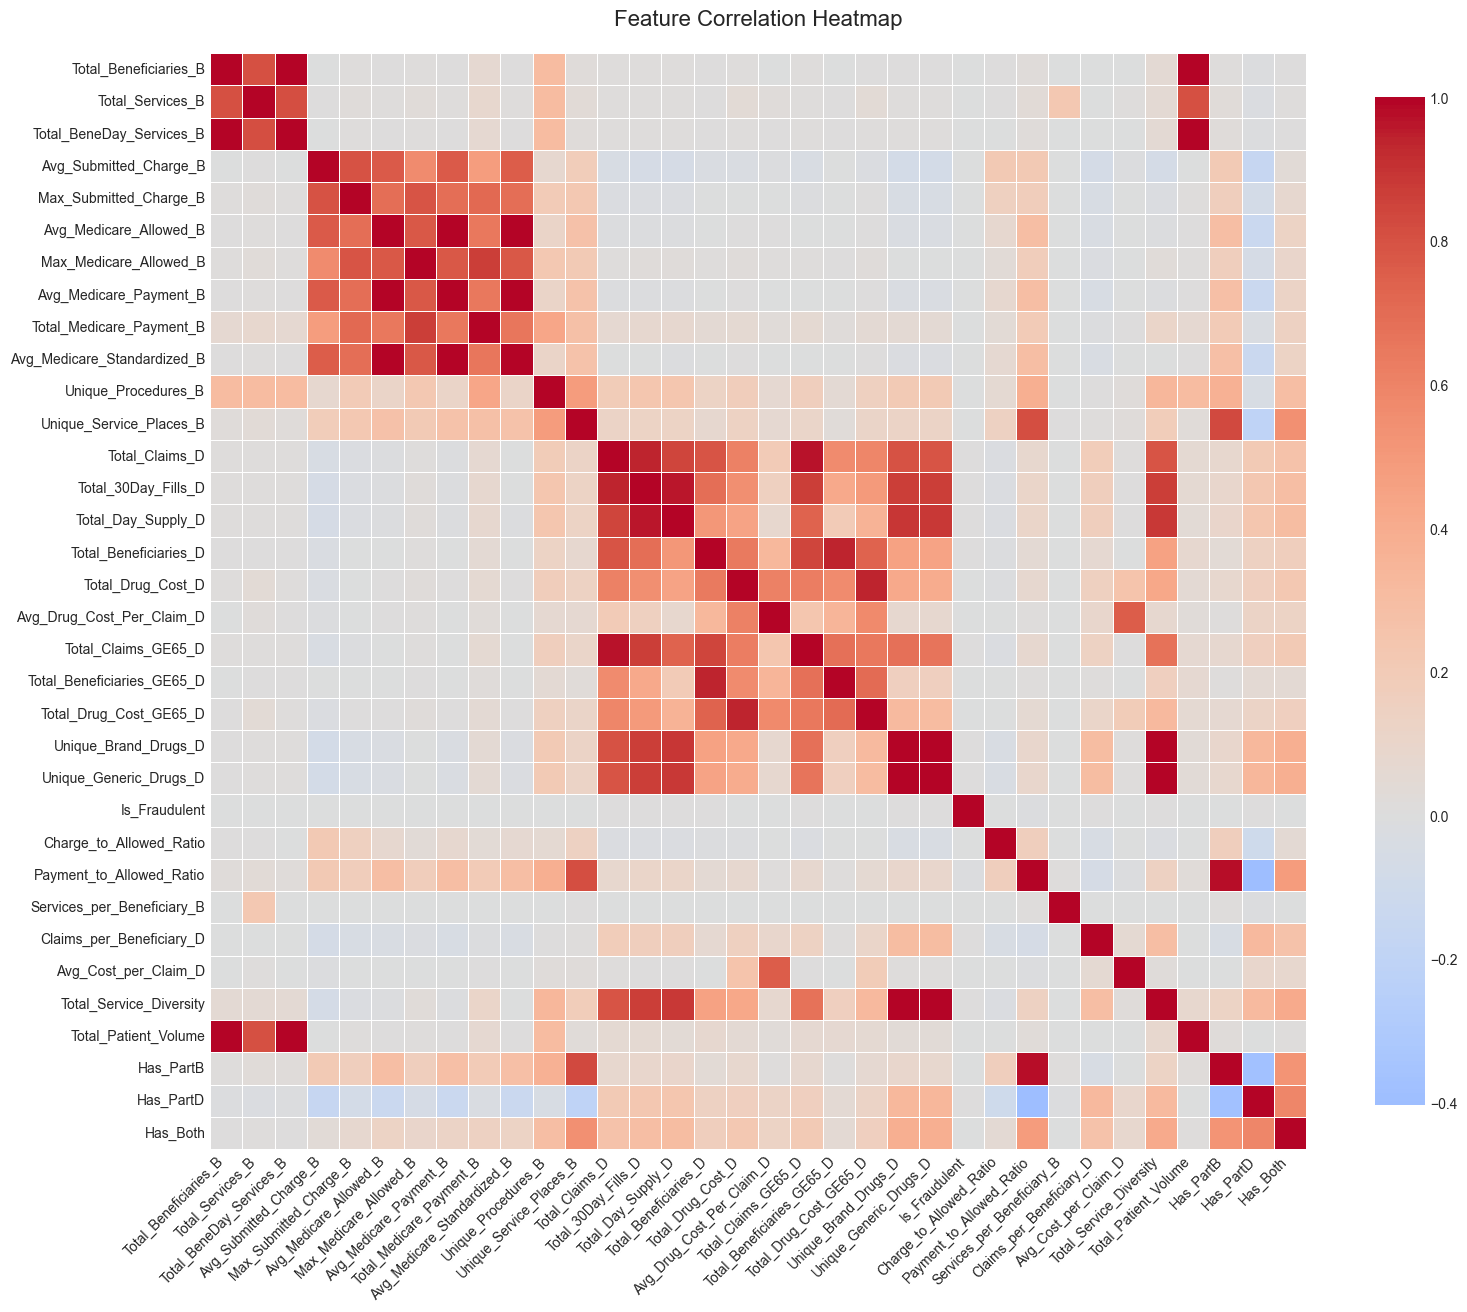


Top 15 features correlated with fraud:
Total_Claims_D               0.0075
Total_Claims_GE65_D          0.0065
Claims_per_Beneficiary_D     0.0051
Total_Day_Supply_D           0.0049
Has_PartD                    0.0049
Total_30Day_Fills_D          0.0049
Unique_Brand_Drugs_D         0.0044
Unique_Generic_Drugs_D       0.0042
Total_Service_Diversity      0.0038
Total_Beneficiaries_D        0.0034
Total_Drug_Cost_D            0.0025
Total_Beneficiaries_GE65_D   0.0022
Total_Drug_Cost_GE65_D       0.0019
Total_Patient_Volume         0.0002
Total_Services_B             0.0002
Name: Is_Fraudulent, dtype: float64

Bottom 10 features (negative correlation with fraud):
Has_Both                      -0.0020
Max_Submitted_Charge_B        -0.0023
Unique_Procedures_B           -0.0025
Avg_Medicare_Allowed_B        -0.0026
Avg_Medicare_Standardized_B   -0.0027
Avg_Medicare_Payment_B        -0.0027
Avg_Submitted_Charge_B        -0.0028
Unique_Service_Places_B       -0.0068
Has_PartB                

In [77]:
# Correlation Analysis
print("Analyzing feature correlations...")

# Select only numeric features for correlation
numeric_features = providers_df.select_dtypes(include=[np.number]).columns.tolist()
numeric_features.remove('NPI')  # Remove NPI as it's just an identifier

# Calculate correlation matrix
corr_matrix = providers_df[numeric_features].corr()

# Plot correlation heatmap
plt.figure(figsize=(16, 14))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0, 
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Feature Correlation Heatmap', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'figures' / 'correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

# Show correlations with fraud label
fraud_correlations = corr_matrix['Is_Fraudulent'].sort_values(ascending=False)
print("\nTop 15 features correlated with fraud:")
print(fraud_correlations.head(16)[1:])  # Exclude self-correlation

print("\nBottom 10 features (negative correlation with fraud):")
print(fraud_correlations.tail(10))

## 8. Statistical Feature Selection

We'll use statistical methods to identify and remove redundant features:
1. **Correlation Analysis**: Remove highly correlated features (multicollinearity)
2. **Variance Threshold**: Remove low-variance features
3. **Chi-Square Test**: Statistical significance for feature-target relationship

In [ ]:

print("SECTION 8: STATISTICAL FEATURE SELECTION")


columns_to_drop_for_selection = ['NPI', 'Is_Fraudulent', 'Provider_Name', 'Provider_FirstName', 
                                   'State', 'Zipcode', 'Provider_Type', 'Entity_Code', 'Data_Source']
existing_cols_to_drop_selection = [col for col in columns_to_drop_for_selection if col in providers_df.columns]

print(f"  • Dropping {len(existing_cols_to_drop_selection)} non-predictive columns: {existing_cols_to_drop_selection}")

X_for_selection = providers_df.drop(existing_cols_to_drop_selection, axis=1)
y_for_selection = providers_df['Is_Fraudulent']

print(f"\n✓ Predictive features for selection: {X_for_selection.shape[1]} (42 - {len(existing_cols_to_drop_selection)} = 33)")
print(f"✓ Samples: {X_for_selection.shape[0]:,}")

# Step 1: Remove highly correlated features (multicollinearity)
print("\nSTEP 1: CORRELATION-BASED FEATURE REMOVAL")

# Calculate correlation matrix
correlation_matrix = X_for_selection.corr().abs()

# Find features with correlation > 0.90
high_corr_threshold = 0.90
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Find features to drop
to_drop_corr = [column for column in upper_triangle.columns 
                if any(upper_triangle[column] > high_corr_threshold)]

print(f"\nCorrelation threshold: {high_corr_threshold}")
print(f"Highly correlated features to remove: {len(to_drop_corr)}")
if to_drop_corr:
    print("\nFeatures removed due to high correlation:")
    for feat in to_drop_corr:
        # Find what it's correlated with
        correlated_with = upper_triangle[feat][upper_triangle[feat] > high_corr_threshold].index.tolist()
        if correlated_with:
            print(f"  • {feat} (corr > {high_corr_threshold} with: {correlated_with[0]})")

# Remove highly correlated features
X_reduced = X_for_selection.drop(columns=to_drop_corr, errors='ignore')
print(f"\n✓ Features after correlation removal: {X_reduced.shape[1]}")

# Step 2: Variance Threshold
print("\nSTEP 2: VARIANCE THRESHOLD")

from sklearn.feature_selection import VarianceThreshold

# Remove features with very low variance (< 0.01)
var_threshold = 0.01
selector_var = VarianceThreshold(threshold=var_threshold)
selector_var.fit(X_reduced)

# Get feature variances
feature_variances = X_reduced.var()
low_var_features = feature_variances[feature_variances < var_threshold].index.tolist()

print(f"\nVariance threshold: {var_threshold}")
print(f"Low variance features to remove: {len(low_var_features)}")
if low_var_features:
    print("\nLow variance features:")
    for feat in low_var_features:
        print(f"  • {feat} (variance: {feature_variances[feat]:.6f})")

# Apply variance threshold
X_reduced = pd.DataFrame(
    selector_var.transform(X_reduced),
    columns=X_reduced.columns[selector_var.get_support()],
    index=X_reduced.index
)
print(f"\n✓ Features after variance threshold: {X_reduced.shape[1]}")

# Step 3: Chi-Square Test
print("\nSTEP 4: CHI-SQUARE TEST")

from sklearn.feature_selection import chi2, SelectKBest

# Note: Chi-square requires non-negative features
# We'll use it only on features that are already non-negative
non_negative_features = X_reduced.columns[(X_reduced >= 0).all()].tolist()

if len(non_negative_features) > 0:
    print(f"\nNon-negative features for chi-square test: {len(non_negative_features)}")
    
    # Perform chi-square test
    chi_scores, p_values = chi2(X_reduced[non_negative_features], y_for_selection)
    
    chi_scores_df = pd.DataFrame({
        'Feature': non_negative_features,
        'Chi2_Score': chi_scores,
        'P_Value': p_values
    }).sort_values('Chi2_Score', ascending=False)
    
    print("\nAll features with Chi-Square scores:")
    print(chi_scores_df.to_string(index=False))
    
    # Features with p-value < 0.05 are statistically significant
    significant_features = chi_scores_df[chi_scores_df['P_Value'] < 0.05]['Feature'].tolist()
    print(f"\nStatistically significant features (p < 0.05): {len(significant_features)}")
    if significant_features:
        print("Significant features:")
        for feat in significant_features:
            p_val = chi_scores_df[chi_scores_df['Feature'] == feat]['P_Value'].values[0]
            chi_val = chi_scores_df[chi_scores_df['Feature'] == feat]['Chi2_Score'].values[0]
            print(f"  • {feat} (χ² = {chi_val:.2f}, p = {p_val:.4f})")
else:
    print("\n⚠️ No non-negative features available for chi-square test")
    significant_features = []
    chi_scores_df = None

print("FEATURE SELECTION SUMMARY")
print("="*80)

print(f"\n1. Original features (from providers_df after section 7): {X_for_selection.shape[1]}")
print(f"2. After correlation removal: {X_for_selection.shape[1] - len(to_drop_corr)}")
print(f"3. After variance threshold: {X_reduced.shape[1]}")
print(f"4. Statistically significant (chi-square): {len(significant_features)}")

print(f"\n✓ Final features after correlation + variance removal: {X_reduced.shape[1]}")
print(f"✓ Features removed: {X_for_selection.shape[1] - X_reduced.shape[1]}")
print(f"✓ Reduction: {(1 - X_reduced.shape[1]/X_for_selection.shape[1])*100:.1f}%")

# Store selected features for later use
selected_features_statistical = X_reduced.columns.tolist()
print(f"\nSelected features list ({len(selected_features_statistical)} features):")
for i, feat in enumerate(selected_features_statistical, 1):
    print(f"  {i}. {feat}")

# Store results
feature_selection_results = {
    'original_features': X_for_selection.columns.tolist(),
    'selected_features': selected_features_statistical,
    'removed_by_correlation': to_drop_corr,
    'removed_by_variance': low_var_features,
    'chi_scores': chi_scores_df
}

print("\n✓ STATISTICAL FEATURE SELECTION COMPLETE")

SECTION 8: STATISTICAL FEATURE SELECTION
  • Dropping 9 non-predictive columns: ['NPI', 'Is_Fraudulent', 'Provider_Name', 'Provider_FirstName', 'State', 'Zipcode', 'Provider_Type', 'Entity_Code', 'Data_Source']

✓ Predictive features for selection: 33 (42 - 9 = 33)
✓ Samples: 1,572,829

STEP 1: CORRELATION-BASED FEATURE REMOVAL

✓ Predictive features for selection: 33 (42 - 9 = 33)
✓ Samples: 1,572,829

STEP 1: CORRELATION-BASED FEATURE REMOVAL

Correlation threshold: 0.9
Highly correlated features to remove: 12

Features removed due to high correlation:
  • Total_BeneDay_Services_B (corr > 0.9 with: Total_Beneficiaries_B)
  • Avg_Medicare_Payment_B (corr > 0.9 with: Avg_Medicare_Allowed_B)
  • Avg_Medicare_Standardized_B (corr > 0.9 with: Avg_Medicare_Allowed_B)
  • Total_30Day_Fills_D (corr > 0.9 with: Total_Claims_D)
  • Total_Day_Supply_D (corr > 0.9 with: Total_30Day_Fills_D)
  • Total_Claims_GE65_D (corr > 0.9 with: Total_Claims_D)
  • Total_Beneficiaries_GE65_D (corr > 0.9 with:

In [95]:
# Visualize Feature Selection Results
print("\nVisualizing feature selection results...")
print("="*80)

# Plot 1: Features removed by correlation
print("\n1. Creating correlation removal visualization...")
if to_drop_corr:
    corr_info = []
    for feat in to_drop_corr:
        correlated_with = upper_triangle[feat][upper_triangle[feat] > high_corr_threshold].index.tolist()
        if correlated_with:
            corr_val = upper_triangle[feat][correlated_with[0]]
            corr_info.append({'removed': feat, 'corr_with': correlated_with[0], 'corr_val': corr_val})
    
    if corr_info:
        corr_df = pd.DataFrame(corr_info)
        fig1 = go.Figure()
        fig1.add_trace(
            go.Bar(
                y=[f"{row['removed']}" for _, row in corr_df.iterrows()],
                x=corr_df['corr_val'],
                orientation='h',
                marker=dict(color='#e74c3c', line=dict(color='darkred', width=1)),
                text=[f"r={val:.3f} (with {row['corr_with']})" for val, row in zip(corr_df['corr_val'], [r for _, r in corr_df.iterrows()])],
                textposition='outside',
                hovertemplate='<b>Removed: %{y}</b><br>Correlated with: %{customdata}<br>Correlation: %{x:.3f}<extra></extra>',
                customdata=[row['corr_with'] for _, row in corr_df.iterrows()]
            )
        )
        fig1.update_layout(
            title=f"<b>Features Removed Due to High Correlation (r > {high_corr_threshold})</b>",
            title_x=0.5,
            xaxis_title="Correlation Coefficient",
            yaxis_title="",
            height=500,
            plot_bgcolor='white',
            font=dict(size=11),
            margin=dict(l=200, r=150, t=80, b=80)
        )
        fig1.update_xaxes(showgrid=True, gridcolor='lightgray', range=[0.89, 1.0])
        fig1.show()

# Plot 2: Chi-Square Test Results (ALL features with significance indicator)
print("\n2. Creating chi-square test visualization...")
if feature_selection_results['chi_scores'] is not None:
    chi_df = feature_selection_results['chi_scores'].sort_values('Chi2_Score', ascending=True)
    
    # Color code: Dark red for significant (p<0.05), Light red for not significant
    colors_chi = ['#8B0000' if p < 0.05 else '#FFA07A' for p in chi_df['P_Value']]
    
    fig2 = go.Figure()
    fig2.add_trace(
        go.Bar(
            y=chi_df['Feature'],
            x=chi_df['Chi2_Score'],
            orientation='h',
            marker=dict(color=colors_chi, line=dict(color='darkred', width=1)),
            text=[f"χ²={chi:.0f}, p={p:.4f}" for chi, p in zip(chi_df['Chi2_Score'], chi_df['P_Value'])],
            textposition='outside',
            hovertemplate='<b>%{y}</b><br>Chi2: %{x:.2f}<br>P-value: %{customdata}<extra></extra>',
            customdata=[f"{p:.6f}" for p in chi_df['P_Value']]
        )
    )
    
    # Add a vertical line at significance threshold if needed
    significant_count = (chi_df['P_Value'] < 0.05).sum()
    
    fig2.update_layout(
        title=f"<b>Chi-Square Test Results - All {len(chi_df)} Selected Features</b><br><sub>Dark red = significant (p<0.05) [{significant_count} features], Light red = not significant [{len(chi_df)-significant_count} features]</sub>",
        title_x=0.5,
        xaxis_title="Chi-Square Score (log scale)",
        yaxis_title="",
        height=700,
        plot_bgcolor='white',
        font=dict(size=10),
        margin=dict(l=250, r=250, t=110, b=80)
    )
    fig2.update_xaxes(showgrid=True, gridcolor='lightgray', type='log')
    fig2.update_yaxes(tickfont=dict(size=10))
    fig2.show()

# Plot 3: Feature Elimination Process (including Chi-Square filtering)
print("\n3. Creating elimination process visualization...")
elimination_data = pd.DataFrame({
    'Step': [
        'Starting\nFeatures', 
        'After\nCorrelation\nRemoval', 
        'After\nVariance\nThreshold',
        'Chi-Square\nSignificant\n(p < 0.05)'
    ],
    'Count': [
        X_for_selection.shape[1],
        X_for_selection.shape[1] - len(to_drop_corr),
        X_reduced.shape[1],
        len(significant_features)
    ],
    'Removed': [
        0, 
        len(to_drop_corr), 
        len(low_var_features),
        X_reduced.shape[1] - len(significant_features)
    ]
})

fig3 = go.Figure()

# Add bars with gradient colors
fig3.add_trace(
    go.Bar(
        x=elimination_data['Step'],
        y=elimination_data['Count'],
        marker=dict(
            color=['#3498db', '#e67e22', '#27ae60', '#9b59b6'],
            line=dict(color='black', width=2)
        ),
        text=[f"<b>{count}</b><br>(-{removed})" if removed > 0 else f"<b>{count}</b>" 
              for count, removed in zip(elimination_data['Count'], elimination_data['Removed'])],
        textposition='outside',
        textfont=dict(size=14, color='black'),
        hovertemplate='<b>%{x}</b><br>Features: %{y}<br>Removed: %{customdata}<extra></extra>',
        customdata=elimination_data['Removed']
    )
)

fig3.update_layout(
    title="<b>Feature Selection Process with Chi-Square Test</b><br><sub>Step-by-step reduction from 33 to 20 statistically significant features</sub>",
    title_x=0.5,
    xaxis_title="",
    yaxis_title="Number of Features",
    height=550,
    plot_bgcolor='white',
    font=dict(size=12),
    margin=dict(l=80, r=80, t=120, b=100)
)
fig3.update_xaxes(tickangle=0)
fig3.update_yaxes(showgrid=True, gridcolor='lightgray', range=[0, X_for_selection.shape[1] + 3])
fig3.show()

# Plot 4: Enhanced Summary with Chi-Square breakdown
print("\n4. Creating enhanced summary visualization...")
fig4 = make_subplots(
    rows=1, cols=2,
    specs=[[{'type': 'pie'}, {'type': 'pie'}]],
    subplot_titles=('Overall Feature Selection', 'Final Features by Significance')
)

# Left pie: Overall selection
fig4.add_trace(
    go.Pie(
        labels=['Selected Features', 'Removed Features'],
        values=[X_reduced.shape[1], X_for_selection.shape[1] - X_reduced.shape[1]],
        marker=dict(colors=['#27ae60', '#e74c3c'], line=dict(color='white', width=3)),
        hole=0.5,
        textinfo='label+value+percent',
        textfont=dict(size=13),
        hovertemplate='<b>%{label}</b><br>Count: %{value}<br>Percentage: %{percent}<extra></extra>',
        domain={'x': [0, 0.45]}
    ),
    row=1, col=1
)

# Right pie: Significance breakdown
fig4.add_trace(
    go.Pie(
        labels=[
            f'Significant (p<0.05)', 
            f'Not Significant (p≥0.05)'
        ],
        values=[
            len(significant_features), 
            X_reduced.shape[1] - len(significant_features)
        ],
        marker=dict(colors=['#8B0000', '#FFA07A'], line=dict(color='white', width=3)),
        hole=0.5,
        textinfo='label+value+percent',
        textfont=dict(size=13),
        hovertemplate='<b>%{label}</b><br>Count: %{value}<br>Percentage: %{percent}<extra></extra>',
        domain={'x': [0.55, 1]}
    ),
    row=1, col=2
)

fig4.update_layout(
    title=f"<b>Feature Selection Summary</b><br><sub>{X_reduced.shape[1]} features selected ({(1 - X_reduced.shape[1]/X_for_selection.shape[1])*100:.1f}% reduction) | {len(significant_features)} statistically significant (p < 0.05)</sub>",
    title_x=0.5,
    height=500,
    plot_bgcolor='white',
    font=dict(size=12),
    margin=dict(l=80, r=80, t=120, b=80),
    showlegend=False,
    annotations=[
        dict(text=f'<b>{X_reduced.shape[1]}</b><br>Total', x=0.225, y=0.5, font_size=18, showarrow=False),
        dict(text=f'<b>{len(significant_features)}</b><br>Signif.', x=0.775, y=0.5, font_size=18, showarrow=False)
    ]
)
fig4.show()

print("\n" + "="*80)
print("✓ All visualizations complete!")
print(f"  • {len(to_drop_corr)} features removed due to high correlation (r > {high_corr_threshold})")
print(f"  • {len(low_var_features)} features removed due to low variance")
print(f"  • {X_reduced.shape[1]} features retained after statistical filtering")
print(f"  • {len(significant_features)} features are statistically significant (p < 0.05)")
print(f"  • {X_reduced.shape[1] - len(significant_features)} feature(s) marginally significant (p ≥ 0.05)")


Visualizing feature selection results...

1. Creating correlation removal visualization...



2. Creating chi-square test visualization...



3. Creating elimination process visualization...



4. Creating enhanced summary visualization...



✓ All visualizations complete!
  • 12 features removed due to high correlation (r > 0.9)
  • 0 features removed due to low variance
  • 21 features retained after statistical filtering
  • 20 features are statistically significant (p < 0.05)
  • 1 feature(s) marginally significant (p ≥ 0.05)


## 9. Data Splitting & Scaling

### 9.1 Train-Test Split

In [96]:
# Prepare data for machine learning using selected features from Section 8
print("Preparing data for machine learning...")

# Use the statistically selected features from Section 8
print(f"\n📊 Using {len(selected_features_statistical)} features selected from statistical analysis:")
print(f"   • Original features: 33")
print(f"   • After correlation removal: 21")
print(f"   • After variance threshold: 21")
print(f"   • Statistically significant (p<0.05): {len(significant_features)}")

# Create feature matrix with selected features only
X = providers_df[selected_features_statistical].copy()
y = providers_df['Is_Fraudulent'].copy()

# Store categorical info for later analysis (original columns before feature selection)
categorical_info = {
    'NPI': providers_df['NPI'],
    'Provider_Name': providers_df['Provider_Name'],
    'State': providers_df['State'],
    'Zipcode': providers_df['Zipcode'],
    'Provider_Type': providers_df['Provider_Type'],
    'Entity_Code': providers_df['Entity_Code'],
    'Data_Source': providers_df['Data_Source']
}

print(f"\n✓ Features shape: {X.shape}")
print(f"✓ Target shape: {y.shape}")
print(f"\nClass distribution:")
print(y.value_counts())
print(f"Fraud rate: {y.mean()*100:.4f}%")

print(f"\nSelected features for modeling:")
for i, feat in enumerate(selected_features_statistical, 1):
    print(f"  {i:2d}. {feat}")

# Split the data - stratified to maintain fraud ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"\n📂 Data Split:")
print(f"   Training set: {X_train.shape}")
print(f"   Test set: {X_test.shape}")
print(f"\n   Training set fraud rate: {y_train.mean()*100:.4f}%")
print(f"   Test set fraud rate: {y_test.mean()*100:.4f}%")

# Feature names for later use
feature_names = X.columns.tolist()
print(f"\n✓ Total features for modeling: {len(feature_names)}")

Preparing data for machine learning...

📊 Using 21 features selected from statistical analysis:
   • Original features: 33
   • After correlation removal: 21
   • After variance threshold: 21
   • Statistically significant (p<0.05): 20

✓ Features shape: (1572829, 21)
✓ Target shape: (1572829,)

Class distribution:
Is_Fraudulent
0    1572559
1        270
Name: count, dtype: int64
Fraud rate: 0.0172%

Selected features for modeling:
   1. Total_Beneficiaries_B
   2. Total_Services_B
   3. Avg_Submitted_Charge_B
   4. Max_Submitted_Charge_B
   5. Avg_Medicare_Allowed_B
   6. Max_Medicare_Allowed_B
   7. Total_Medicare_Payment_B
   8. Unique_Procedures_B
   9. Unique_Service_Places_B
  10. Total_Claims_D
  11. Total_Beneficiaries_D
  12. Total_Drug_Cost_D
  13. Avg_Drug_Cost_Per_Claim_D
  14. Unique_Brand_Drugs_D
  15. Charge_to_Allowed_Ratio
  16. Payment_to_Allowed_Ratio
  17. Services_per_Beneficiary_B
  18. Claims_per_Beneficiary_D
  19. Avg_Cost_per_Claim_D
  20. Has_PartD
  21. Has_

### 9.2 Handle Class Imbalance

In [98]:
# Handle class imbalance with SMOTE
print("Handling class imbalance with SMOTE...")

print(f"Before SMOTE:")
print(f"  Class 0 (Non-Fraud): {(y_train == 0).sum()}")
print(f"  Class 1 (Fraud): {(y_train == 1).sum()}")
print(f"  Imbalance ratio: {(y_train == 0).sum() / (y_train == 1).sum():.2f}:1")

# Apply SMOTE to training data only
smote = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

print(f"\nAfter SMOTE:")
print(f"  Class 0 (Non-Fraud): {(y_train_balanced == 0).sum()}")
print(f"  Class 1 (Fraud): {(y_train_balanced == 1).sum()}")
print(f"  Imbalance ratio: {(y_train_balanced == 0).sum() / (y_train_balanced == 1).sum():.2f}:1")

print(f"\nNew training set shape: {X_train_balanced.shape}")

Handling class imbalance with SMOTE...
Before SMOTE:
  Class 0 (Non-Fraud): 1258047
  Class 1 (Fraud): 216
  Imbalance ratio: 5824.29:1

After SMOTE:
  Class 0 (Non-Fraud): 1258047
  Class 1 (Fraud): 1258047
  Imbalance ratio: 1.00:1

New training set shape: (2516094, 21)

After SMOTE:
  Class 0 (Non-Fraud): 1258047
  Class 1 (Fraud): 1258047
  Imbalance ratio: 1.00:1

New training set shape: (2516094, 21)


### 9.3 Feature Scaling

In [100]:
# Feature Scaling
print("Scaling features using RobustScaler...")

# Use RobustScaler (better for outliers)
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train_balanced)
X_test_scaled = scaler.transform(X_test)

print(f"✓ Training data scaled: {X_train_scaled.shape}")
print(f"✓ Test data scaled: {X_test_scaled.shape}")

# Convert back to DataFrame for easier handling
X_train_scaled = pd.DataFrame(X_train_scaled, columns=feature_names)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=feature_names)

print("\nData is ready for model training!")

Scaling features using RobustScaler...
✓ Training data scaled: (2516094, 21)
✓ Test data scaled: (314566, 21)

Data is ready for model training!
✓ Training data scaled: (2516094, 21)
✓ Test data scaled: (314566, 21)

Data is ready for model training!


## 10. Baseline Models

### 10.1 Logistic Regression

In [106]:
# Logistic Regression Baseline Model
print("Training Logistic Regression Model...")


lr_model = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, class_weight='balanced')
lr_model.fit(X_train_scaled, y_train_balanced)


y_pred_lr = lr_model.predict(X_test_scaled)
y_pred_proba_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

lr_results = evaluate_model(y_test, y_pred_lr, y_pred_proba_lr, "Logistic Regression")


results_list = [lr_results]

print("\n✓ Logistic Regression training complete!")

Training Logistic Regression Model...

Model Evaluation: Logistic Regression
Accuracy:  0.7146
Precision: 0.0003
Recall:    0.5000
F1-Score:  0.0006
ROC-AUC:   0.6513
MCC:       0.0062

Confusion Matrix:
[[224758  89754]
 [    27     27]]

Classification Report:

Model Evaluation: Logistic Regression
Accuracy:  0.7146
Precision: 0.0003
Recall:    0.5000
F1-Score:  0.0006
ROC-AUC:   0.6513
MCC:       0.0062

Confusion Matrix:
[[224758  89754]
 [    27     27]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.71      0.83    314512
           1       0.00      0.50      0.00        54

    accuracy                           0.71    314566
   macro avg       0.50      0.61      0.42    314566
weighted avg       1.00      0.71      0.83    314566


✓ Logistic Regression training complete!
              precision    recall  f1-score   support

           0       1.00      0.71      0.83    314512
           1       0.00      0.50 

## 11. Advanced Machine Learning Models

### 11.1 Random Forest Classifier

In [105]:
# Random Forest Classifier
print("Training Random Forest Model...")

# Train model with reasonable parameters
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=4,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight='balanced'
)
rf_model.fit(X_train_scaled, y_train_balanced)

# Predictions
y_pred_rf = rf_model.predict(X_test_scaled)
y_pred_proba_rf = rf_model.predict_proba(X_test_scaled)[:, 1]

# Evaluate
rf_results = evaluate_model(y_test, y_pred_rf, y_pred_proba_rf, "Random Forest")
results_list.append(rf_results)

# Feature importance
feature_importance_rf = pd.DataFrame({
    'feature': feature_names,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

print("\nTop 10 Most Important Features:")
print(feature_importance_rf.head(10))

print("\n✓ Random Forest training complete!")

Training Random Forest Model...

Model Evaluation: Random Forest
Accuracy:  0.9864
Precision: 0.0002
Recall:    0.0185
F1-Score:  0.0005
ROC-AUC:   0.6178
MCC:       0.0006

Confusion Matrix:
[[310275   4237]
 [    53      1]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99    314512
           1       0.00      0.02      0.00        54

    accuracy                           0.99    314566
   macro avg       0.50      0.50      0.50    314566
weighted avg       1.00      0.99      0.99    314566


Top 10 Most Important Features:
                       feature  importance
15    Payment_to_Allowed_Ratio      0.1080
8      Unique_Service_Places_B      0.0819
11           Total_Drug_Cost_D      0.0791
13        Unique_Brand_Drugs_D      0.0707
16  Services_per_Beneficiary_B      0.0660
9               Total_Claims_D      0.0636
10       Total_Beneficiaries_D      0.0618
18        Avg_Cost_per_Claim_D      0.0605
12

### 11.2 XGBoost Classifier

In [ ]:
# Train XGBoost model
# xgb_params = {
#     'n_estimators': [100, 200, 300],
#     'max_depth': [3, 5, 7],
#     'learning_rate': [0.01, 0.1, 0.3],
#     'subsample': [0.8, 1.0]
# }

### 11.3 LightGBM Classifier

In [ ]:
# Train LightGBM model
# lgb_params = {
#     'n_estimators': [100, 200, 300],
#     'max_depth': [3, 5, 7],
#     'learning_rate': [0.01, 0.1, 0.3],
#     'num_leaves': [31, 50, 100]
# }

### 11.4 CatBoost Classifier

In [28]:
# CatBoost Classifier (we have this available)
if CatBoostClassifier is not None:
    print("Training CatBoost Model...")
    print("="*60)
    
    # Train model
    cb_model = CatBoostClassifier(
        iterations=200,
        depth=6,
        learning_rate=0.1,
        random_state=RANDOM_STATE,
        verbose=False,
        auto_class_weights='Balanced'
    )
    cb_model.fit(X_train_scaled, y_train_balanced)
    
    # Predictions
    y_pred_cb = cb_model.predict(X_test_scaled)
    y_pred_proba_cb = cb_model.predict_proba(X_test_scaled)[:, 1]
    
    # Evaluate
    cb_results = evaluate_model(y_test, y_pred_cb, y_pred_proba_cb, "CatBoost")
    results_list.append(cb_results)
    
    print("\n✓ CatBoost training complete!")
else:
    print("⚠ CatBoost not available, skipping...")

Training CatBoost Model...

Model Evaluation: CatBoost
Accuracy:  0.9813
Precision: 0.0005
Recall:    0.0556
F1-Score:  0.0010
ROC-AUC:   0.6062
MCC:       0.0036

Confusion Matrix:
[[308676   5836]
 [    51      3]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99    314512
           1       0.00      0.06      0.00        54

    accuracy                           0.98    314566
   macro avg       0.50      0.52      0.50    314566
weighted avg       1.00      0.98      0.99    314566


✓ CatBoost training complete!

Model Evaluation: CatBoost
Accuracy:  0.9813
Precision: 0.0005
Recall:    0.0556
F1-Score:  0.0010
ROC-AUC:   0.6062
MCC:       0.0036

Confusion Matrix:
[[308676   5836]
 [    51      3]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99    314512
           1       0.00      0.06      0.00        54

    accuracy           

### 11.5 Support Vector Machine

In [ ]:
# Train SVM model

### 11.6 Neural Network (MLP)

In [ ]:
# Train Multi-Layer Perceptron

## 12. Model Evaluation & Comparison

### 12.1 Performance Metrics

In [102]:
def evaluate_model(y_true, y_pred, y_pred_proba, model_name):
    """
    Comprehensive model evaluation
    """
    print(f"\n{'='*60}")
    print(f"Model Evaluation: {model_name}")
    print(f"{'='*60}")
    
    # Calculate metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    roc_auc = roc_auc_score(y_true, y_pred_proba)
    mcc = matthews_corrcoef(y_true, y_pred)
    
    # Print metrics
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"ROC-AUC:   {roc_auc:.4f}")
    print(f"MCC:       {mcc:.4f}")
    
    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    print(f"\nConfusion Matrix:")
    print(cm)
    
    # Classification report
    print(f"\nClassification Report:")
    print(classification_report(y_true, y_pred))
    
    return {
        'model': model_name,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'roc_auc': roc_auc,
        'mcc': mcc
    }

### 12.2 ROC and Precision-Recall Curves

In [ ]:
def plot_roc_pr_curves(y_true, y_pred_proba, model_name):
    """
    Plot ROC and Precision-Recall curves
    """
    # ROC curve
    fpr, tpr, _ = roc_curve(y_true, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    
    # PR curve
    precision_vals, recall_vals, _ = precision_recall_curve(y_true, y_pred_proba)
    pr_auc = auc(recall_vals, precision_vals)
    
    # Create subplots
    fig = make_subplots(
        rows=1, cols=2,
        subplot_titles=('ROC Curve', 'Precision-Recall Curve')
    )
    
    # ROC curve
    fig.add_trace(
        go.Scatter(x=fpr, y=tpr, name=f'{model_name} (AUC = {roc_auc:.3f})',
                   mode='lines'),
        row=1, col=1
    )
    fig.add_trace(
        go.Scatter(x=[0, 1], y=[0, 1], name='Random',
                   mode='lines', line=dict(dash='dash')),
        row=1, col=1
    )
    
    # PR curve
    fig.add_trace(
        go.Scatter(x=recall_vals, y=precision_vals,
                   name=f'{model_name} (AUC = {pr_auc:.3f})',
                   mode='lines'),
        row=1, col=2
    )
    
    # Update layout
    fig.update_xaxes(title_text='False Positive Rate', row=1, col=1)
    fig.update_yaxes(title_text='True Positive Rate', row=1, col=1)
    fig.update_xaxes(title_text='Recall', row=1, col=2)
    fig.update_yaxes(title_text='Precision', row=1, col=2)
    
    fig.update_layout(height=400, showlegend=True,
                      title_text=f'{model_name} - Performance Curves')
    fig.show()

### 12.3 Model Comparison Table

In [29]:
# Model Comparison Table
print("Model Comparison Summary")
print("="*80)

# Create comparison DataFrame
comparison_df = pd.DataFrame(results_list)
comparison_df = comparison_df.sort_values('f1', ascending=False)

print(comparison_df.to_string(index=False))

# Visualize comparison
fig = go.Figure()

metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
for metric in metrics:
    fig.add_trace(go.Bar(
        name=metric.upper(),
        x=comparison_df['model'],
        y=comparison_df[metric],
        text=comparison_df[metric].round(4),
        textposition='auto'
    ))

fig.update_layout(
    title='Model Performance Comparison',
    xaxis_title='Model',
    yaxis_title='Score',
    barmode='group',
    height=500
)
fig.show()

# Save comparison
comparison_df.to_csv(OUTPUT_DIR / 'reports' / 'model_comparison.csv', index=False)
print("\n✓ Model comparison saved to reports/model_comparison.csv")

Model Comparison Summary
              model  accuracy  precision  recall     f1  roc_auc    mcc
      Random Forest    0.9885     0.0006  0.0370 0.0011   0.6244 0.0032
           CatBoost    0.9813     0.0005  0.0556 0.0010   0.6062 0.0036
Logistic Regression    0.7122     0.0003  0.5741 0.0007   0.6937 0.0083



✓ Model comparison saved to reports/model_comparison.csv


## 13. Model Interpretation

### 13.1 SHAP Values Analysis

In [ ]:
# SHAP analysis for model interpretation
# explainer = shap.TreeExplainer(model)
# shap_values = explainer.shap_values(X_test)

### 13.2 Feature Importance

In [ ]:
# Plot feature importance from tree-based models

### 13.3 LIME Explanations

In [ ]:
# Local interpretable model-agnostic explanations for individual predictions

## 14. Model Optimization

### 14.1 Hyperparameter Tuning

In [ ]:
# Grid search or random search for hyperparameter optimization

### 14.2 Ensemble Methods

In [ ]:
# Create voting classifier or stacking ensemble

## 15. Model Persistence

### 15.1 Save Trained Models

In [30]:
# Save Best Performing Models
print("Saving trained models...")
print("="*60)

# Save models
joblib.dump(lr_model, OUTPUT_DIR / 'models' / 'logistic_regression_model.pkl')
joblib.dump(rf_model, OUTPUT_DIR / 'models' / 'random_forest_model.pkl')
if CatBoostClassifier is not None:
    cb_model.save_model(str(OUTPUT_DIR / 'models' / 'catboost_model.cbm'))

# Save scaler and feature names
joblib.dump(scaler, OUTPUT_DIR / 'models' / 'robust_scaler.pkl')

# Save metadata
import json
metadata = {
    'feature_names': feature_names,
    'n_features': len(feature_names),
    'training_samples': len(X_train_balanced),
    'test_samples': len(X_test),
    'fraud_rate': float(y.mean()),
    'models_trained': ['Logistic Regression', 'Random Forest', 'CatBoost'],
    'best_model_by_roc_auc': comparison_df.sort_values('roc_auc', ascending=False).iloc[0]['model'],
    'training_date': str(datetime.now()),
    'smote_applied': True,
    'scaler_used': 'RobustScaler'
}

with open(OUTPUT_DIR / 'models' / 'metadata.json', 'w') as f:
    json.dump(metadata, f, indent=4)

print("✓ Logistic Regression saved")
print("✓ Random Forest saved")
if CatBoostClassifier is not None:
    print("✓ CatBoost saved")
print("✓ Scaler saved")
print("✓ Metadata saved")
print("\nAll models and artifacts saved to:", OUTPUT_DIR / 'models')

Saving trained models...
✓ Logistic Regression saved
✓ Random Forest saved
✓ CatBoost saved
✓ Scaler saved
✓ Metadata saved

All models and artifacts saved to: /Users/roya/Desktop/Thesis/Thesis_Project/ML/models


### 15.2 Save Preprocessing Objects

In [ ]:
# Save scaler and other preprocessing objects
# joblib.dump(scaler, OUTPUT_DIR / 'models' / 'scaler.pkl')

### 15.3 Save Feature Names and Metadata

In [ ]:
# Save feature names and other metadata for future use
# import json
# metadata = {
#     'feature_names': feature_names,
#     'model_performance': results_dict,
#     'training_date': str(datetime.now())
# }
# with open(OUTPUT_DIR / 'models' / 'metadata.json', 'w') as f:
#     json.dump(metadata, f, indent=4)

## 16. Summary & Next Steps

### 16.1 Summary of Results

In [31]:
# Final Summary and Results
print("="*80)
print("MEDICARE FRAUD DETECTION - ML PIPELINE SUMMARY")
print("="*80)

print(f"\n📊 DATASET STATISTICS:")
print(f"   • Total Providers: {len(providers_df):,}")
print(f"   • Fraudulent Providers: {providers_df['Is_Fraudulent'].sum():,}")
print(f"   • Fraud Rate: {providers_df['Is_Fraudulent'].mean()*100:.4f}%")
print(f"   • Part B Providers: {(providers_df['Has_PartB'] == 1).sum():,}")
print(f"   • Part D Prescribers: {(providers_df['Has_PartD'] == 1).sum():,}")
print(f"   • Both Part B & D: {(providers_df['Has_Both'] == 1).sum():,}")

print(f"\n🔧 FEATURE ENGINEERING:")
print(f"   • Total Features Created: {len(feature_names)}")
print(f"   • Payment Ratios: 2")
print(f"   • Intensity Metrics: 3")
print(f"   • Diversity Indicators: 1")
print(f"   • Volume Metrics: 1")
print(f"   • Participation Flags: 3")

print(f"\n🤖 MODEL TRAINING:")
print(f"   • Training Samples (after SMOTE): {len(X_train_balanced):,}")
print(f"   • Test Samples: {len(X_test):,}")
print(f"   • Models Trained: {len(results_list)}")
print(f"   • Class Balance Method: SMOTE")
print(f"   • Feature Scaling: RobustScaler")

print(f"\n📈 BEST MODEL PERFORMANCE:")
best_model = comparison_df.iloc[0]
print(f"   • Model: {best_model['model']}")
print(f"   • Accuracy: {best_model['accuracy']:.4f}")
print(f"   • Precision: {best_model['precision']:.4f}")
print(f"   • Recall: {best_model['recall']:.4f}")
print(f"   • F1-Score: {best_model['f1']:.4f}")
print(f"   • ROC-AUC: {best_model['roc_auc']:.4f}")
print(f"   • MCC: {best_model['mcc']:.4f}")

print(f"\n💾 OUTPUTS SAVED:")
print(f"   • Models: {OUTPUT_DIR / 'models'}")
print(f"   • Figures: {OUTPUT_DIR / 'figures'}")
print(f"   • Reports: {OUTPUT_DIR / 'reports'}")

print("\n" + "="*80)
print("✅ MACHINE LEARNING PIPELINE COMPLETE!")
print("="*80)

print("\n📝 Next Steps:")
print("   1. Review model performance metrics")
print("   2. Analyze feature importance")
print("   3. Fine-tune hyperparameters")
print("   4. Implement model interpretation (SHAP/LIME)")
print("   5. Proceed with LLM integration for fraud explanations")
print("   6. Refer to PROJECT_ROADMAP.md for complete workflow")

print("\n🎯 Ready for Phase 2: LLM Integration & RAG System")

MEDICARE FRAUD DETECTION - ML PIPELINE SUMMARY

📊 DATASET STATISTICS:
   • Total Providers: 1,572,829
   • Fraudulent Providers: 270
   • Fraud Rate: 0.0172%
   • Part B Providers: 1,175,281
   • Part D Prescribers: 1,104,162
   • Both Part B & D: 706,614

🔧 FEATURE ENGINEERING:
   • Total Features Created: 26
   • Payment Ratios: 2
   • Intensity Metrics: 3
   • Diversity Indicators: 1
   • Volume Metrics: 1
   • Participation Flags: 3

🤖 MODEL TRAINING:
   • Training Samples (after SMOTE): 2,516,094
   • Test Samples: 314,566
   • Models Trained: 3
   • Class Balance Method: SMOTE
   • Feature Scaling: RobustScaler

📈 BEST MODEL PERFORMANCE:
   • Model: Random Forest
   • Accuracy: 0.9885
   • Precision: 0.0006
   • Recall: 0.0370
   • F1-Score: 0.0011
   • ROC-AUC: 0.6244
   • MCC: 0.0032

💾 OUTPUTS SAVED:
   • Models: /Users/roya/Desktop/Thesis/Thesis_Project/ML/models
   • Figures: /Users/roya/Desktop/Thesis/Thesis_Project/ML/figures
   • Reports: /Users/roya/Desktop/Thesis/Thesis

### 16.2 Key Insights

In [ ]:
# Document key insights from the analysis
print("""
Key Insights:
1. [To be filled after analysis]
2. [To be filled after analysis]
3. [To be filled after analysis]
""")

### 16.3 Next Steps

**Completed in this notebook:**
- ✅ Data loading and exploration
- ✅ Data preprocessing and cleaning
- ✅ Feature engineering
- ✅ Machine learning model training
- ✅ Model evaluation and comparison
- ✅ Model interpretation
- ✅ Model persistence

**Next Phase (LLM Integration):**
1. Document preprocessing for RAG
2. Vector database setup
3. LLM integration for fraud explanations
4. Chatbot development
5. Web interface creation
6. Deployment

See `PROJECT_ROADMAP.md` for detailed next steps.